# C03e — Long-word share audit

Fresh-kernel audit after **C03d Step 7.5 (NUM)**.

This notebook makes **no text edits**, performs **no generation**, and does **not refit the detector**. It starts from the accepted final NUM texts and audits the direction of `share_long_words` against the same-genre RAID test-human reference pools used by the current FZ186 evaluation.

Project definition inherited from the frozen FZ118 extractor:

\[
\texttt{share\_long\_words}
=
\frac{\#\{\text{alphabetic tokens with length}\ge 7\}}
{\#\{\text{alphabetic tokens}\}}.
\]

The goal here is only to answer: **are the current post-NUM texts too high or too low in long-word share, globally and by genre?**

Outputs are written under:

`results/causal/C03e_long_word_audit/`

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import spacy
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
assert (ROOT / "results").exists(), "Open from repository root or experiments/"

FINAL_DIR = ROOT / "results/causal/C03d_NUM_final_years/3e7f9d9e6268"
INPUT = FINAL_DIR / "accepted_texts_and_scores.csv"

BASE = ROOT / "results/causal/C02d2_fz118_ghostbuster_raid"
FEATURES = BASE / "fz118_paired_features.parquet"

# Freeze the same spaCy environment used by the canonical C03 FZ186 run.
c03_runs = sorted(p.parent for p in (ROOT / "results/causal/C03_fz186_raid_fixed54").glob("*/feature_manifest.json"))
if len(c03_runs) != 1:
    raise RuntimeError(f"Expected one canonical C03 run; found: {c03_runs}")
C03_RUN = c03_runs[0]
manifest = json.loads((C03_RUN / "feature_manifest.json").read_text())

OUT = ROOT / "results/causal/C03e_long_word_audit"
OUT.mkdir(parents=True, exist_ok=True)

assert INPUT.exists(), f"Missing final C03d input: {INPUT}"
assert FEATURES.exists(), f"Missing frozen FZ118 feature table: {FEATURES}"

texts = pd.read_csv(INPUT, keep_default_na=False).sort_values("case_id").reset_index(drop=True)
assert len(texts) == 54
assert texts["case_id"].is_unique
assert texts["pipeline_status"].eq("complete").all()

fz = pd.read_parquet(FEATURES)
raid = fz.loc[fz["dataset"].eq("raid")].copy()

humans = raid.loc[
    raid["split"].eq("test")
    & raid["label"].eq(0)
    & raid["domain"].isin(texts["domain"].unique())
].copy()

assert len(humans) > 0
assert "share_long_words" in humans.columns
assert "n_long_words" in humans.columns
assert "n_words" in humans.columns

nlp = spacy.load("en_core_web_sm")
assert nlp.meta == manifest["spacy"], "spaCy model/version differs from canonical C03 extraction"

print("Canonical C03 run:", C03_RUN)
print("Final C03d input:", INPUT)
print("AI documents:", len(texts))
print("Human test references:", len(humans))
print("Domains:", sorted(texts["domain"].unique()))

Canonical C03 run: ../results/causal/C03_fz186_raid_fixed54/cfa99a0382fb
Final C03d input: ../results/causal/C03d_NUM_final_years/3e7f9d9e6268/accepted_texts_and_scores.csv
AI documents: 54
Human test references: 128
Domains: ['abstracts', 'books', 'news', 'recipes', 'reddit', 'reviews', 'wiki']


In [2]:
# Exact inherited definition needed for this audit only.
# C02t/FZ118 uses alphabetic spaCy tokens; long words have >= 7 characters.

def long_word_stats(text):
    doc = nlp(str(text))
    words = [tok.text.lower() for tok in doc if tok.is_alpha]
    n_words = len(words)
    n_long = sum(len(w) >= 7 for w in words)
    share = (n_long / n_words) if n_words else 0.0
    return n_words, n_long, share

rows = []
for r in texts.itertuples(index=False):
    n_words, n_long, share = long_word_stats(r.text)
    rows.append({
        "case_id": r.case_id,
        "source_id": r.source_id,
        "domain": r.domain,
        "n_words": n_words,
        "n_long_words": n_long,
        "share_long_words": share,
        "post_NUM_AI_score": float(r.post_NUM_AI_score),
    })

ai = pd.DataFrame(rows)

# Same-genre frozen human reference summaries.
human_by_domain = (
    humans.groupby("domain")["share_long_words"]
    .agg(
        human_n="size",
        human_mean="mean",
        human_median="median",
        human_min="min",
        human_max="max",
    )
)

qs = (
    humans.groupby("domain")["share_long_words"]
    .quantile([0.10, 0.25, 0.75, 0.90])
    .unstack()
    .rename(columns={
        0.10: "human_q10",
        0.25: "human_q25",
        0.75: "human_q75",
        0.90: "human_q90",
    })
)

human_by_domain = human_by_domain.join(qs).reset_index()

audit = ai.merge(human_by_domain, on="domain", how="left", validate="many_to_one")
assert audit["human_mean"].notna().all()

audit["delta_vs_human_mean"] = audit["share_long_words"] - audit["human_mean"]
audit["delta_vs_human_median"] = audit["share_long_words"] - audit["human_median"]

audit["side_of_median"] = np.select(
    [
        audit["delta_vs_human_median"] > 1e-12,
        audit["delta_vs_human_median"] < -1e-12,
    ],
    ["above", "below"],
    default="equal",
)

audit["band_position"] = np.select(
    [
        audit["share_long_words"] < audit["human_q10"],
        audit["share_long_words"] < audit["human_q25"],
        audit["share_long_words"] <= audit["human_q75"],
        audit["share_long_words"] <= audit["human_q90"],
    ],
    ["below_q10", "q10_to_q25", "q25_to_q75", "q75_to_q90"],
    default="above_q90",
)

audit.to_csv(OUT / "long_word_case_audit.csv", index=False)

display(
    audit[
        [
            "case_id", "domain",
            "n_words", "n_long_words", "share_long_words",
            "human_mean", "human_median",
            "human_q10", "human_q25", "human_q75", "human_q90",
            "delta_vs_human_mean", "delta_vs_human_median",
            "side_of_median", "band_position",
        ]
    ].sort_values(["domain", "delta_vs_human_median"])
)

,case_id,domain,n_words,n_long_words,share_long_words,human_mean,human_median,human_q10,human_q25,human_q75,human_q90,delta_vs_human_mean,delta_vs_human_median,side_of_median,band_position
38,gate_0074,abstracts,87,22,0.252874,0.371174,0.370787,0.320519,0.348316,0.391437,0.425104,-0.118300,-0.117913,below,below_q10
0,gate_0001,abstracts,140,50,0.357143,0.371174,0.370787,0.320519,0.348316,0.391437,0.425104,-0.014031,-0.013644,below,q25_to_q75
49,gate_0090,abstracts,156,59,0.378205,0.371174,0.370787,0.320519,0.348316,0.391437,0.425104,0.007031,0.007419,above,q25_to_q75
50,gate_0092,abstracts,132,51,0.386364,0.371174,0.370787,0.320519,0.348316,0.391437,0.425104,0.015190,0.015577,above,q25_to_q75
5,gate_0015,abstracts,186,75,0.403226,0.371174,0.370787,0.320519,0.348316,0.391437,0.425104,0.032052,0.032439,above,q75_to_q90
42,gate_0079,abstracts,125,55,0.440000,0.371174,0.370787,0.320519,0.348316,0.391437,0.425104,0.068826,0.069213,above,above_q90
35,gate_0069,abstracts,103,46,0.446602,0.371174,0.370787,0.320519,0.348316,0.391437,0.425104,0.075428,0.075815,above,above_q90
12,gate_0022,abstracts,129,58,0.449612,0.371174,0.370787,0.320519,0.348316,0.391437,0.425104,0.078438,0.078826,above,above_q90
18,gate_0028,abstracts,152,70,0.460526,0.371174,0.370787,0.320519,0.348316,0.391437,0.425104,0.089352,0.089740,above,above_q90
24,gate_0046,abstracts,117,59,0.504274,0.371174,0.370787,0.320519,0.348316,0.391437,0.425104,0.133100,0.133487,above,above_q90


In [3]:
# Direction summary: by genre and overall, controlling for the current 54-document genre mix.

domain_ai = (
    audit.groupby("domain")
    .agg(
        ai_n=("case_id", "size"),
        ai_mean=("share_long_words", "mean"),
        ai_median=("share_long_words", "median"),
        mean_delta_vs_human_mean=("delta_vs_human_mean", "mean"),
        median_delta_vs_human_median=("delta_vs_human_median", "median"),
        n_above_human_median=("side_of_median", lambda s: int((s == "above").sum())),
        n_below_human_median=("side_of_median", lambda s: int((s == "below").sum())),
    )
    .reset_index()
)

# Fill tail counts directly from audit so the row-specific same-genre bounds are used.
tail = (
    audit.assign(
        above_q75=audit["share_long_words"] > audit["human_q75"],
        below_q25=audit["share_long_words"] < audit["human_q25"],
    )
    .groupby("domain")
    .agg(
        n_above_q75=("above_q75", "sum"),
        n_below_q25=("below_q25", "sum"),
    )
    .reset_index()
)

domain_ai = domain_ai.merge(
    tail, on="domain", how="left"
).merge(
    human_by_domain[
        ["domain", "human_n", "human_mean", "human_median",
         "human_q10", "human_q25", "human_q75", "human_q90"]
    ],
    on="domain", how="left", validate="one_to_one"
)

domain_ai["mean_gap"] = domain_ai["ai_mean"] - domain_ai["human_mean"]
domain_ai["median_gap"] = domain_ai["ai_median"] - domain_ai["human_median"]
domain_ai["mean_direction"] = np.where(
    domain_ai["mean_gap"] > 0, "ABOVE",
    np.where(domain_ai["mean_gap"] < 0, "BELOW", "EQUAL")
)

domain_ai.to_csv(OUT / "long_word_domain_summary.csv", index=False)
display(domain_ai.sort_values("mean_gap", ascending=False))

# Genre-matched overall comparison.
mix = audit["domain"].value_counts(normalize=True)
human_mean_by_domain = humans.groupby("domain")["share_long_words"].mean()
genre_matched_human_mean = float(
    sum(mix[d] * human_mean_by_domain[d] for d in mix.index)
)

ai_mean = float(audit["share_long_words"].mean())
overall_gap = ai_mean - genre_matched_human_mean

above = int((audit["side_of_median"] == "above").sum())
below = int((audit["side_of_median"] == "below").sum())
equal = int((audit["side_of_median"] == "equal").sum())
above_q75 = int((audit["share_long_words"] > audit["human_q75"]).sum())
below_q25 = int((audit["share_long_words"] < audit["human_q25"]).sum())
above_q90 = int((audit["share_long_words"] > audit["human_q90"]).sum())
below_q10 = int((audit["share_long_words"] < audit["human_q10"]).sum())

direction = "ABOVE" if overall_gap > 0 else ("BELOW" if overall_gap < 0 else "EQUAL")

summary = pd.DataFrame([{
    "ai_mean_share_long_words": ai_mean,
    "genre_matched_human_mean": genre_matched_human_mean,
    "mean_gap_ai_minus_human": overall_gap,
    "overall_direction": direction,
    "cases_above_same_genre_median": above,
    "cases_below_same_genre_median": below,
    "cases_equal_same_genre_median": equal,
    "cases_above_same_genre_q75": above_q75,
    "cases_below_same_genre_q25": below_q25,
    "cases_above_same_genre_q90": above_q90,
    "cases_below_same_genre_q10": below_q10,
}])

summary.to_csv(OUT / "long_word_overall_summary.csv", index=False)
display(summary)

print()
print("=" * 72)
print(f"POST-NUM LONG-WORD DIRECTION: {direction}")
print(f"AI mean share_long_words:           {ai_mean:.6f}")
print(f"Genre-matched human mean:           {genre_matched_human_mean:.6f}")
print(f"AI - human mean gap:                {overall_gap:+.6f}")
print(f"Above / below same-genre median:    {above} / {below}  (equal: {equal})")
print(f"Above Q75 / below Q25:              {above_q75} / {below_q25}")
print(f"Above Q90 / below Q10:              {above_q90} / {below_q10}")
print("=" * 72)

,domain,ai_n,ai_mean,ai_median,mean_delta_vs_human_mean,median_delta_vs_human_median,n_above_human_median,n_below_human_median,n_above_q75,n_below_q25,human_n,human_mean,human_median,human_q10,human_q25,human_q75,human_q90,mean_gap,median_gap,mean_direction
5,reviews,1,0.279365,0.279365,0.088966,0.088033,1,0,1,0,6,0.190400,0.191332,0.158751,0.168065,0.202651,0.221116,0.088966,0.088033,ABOVE
2,news,12,0.303241,0.328801,0.063317,0.072918,11,1,10,1,25,0.239924,0.255882,0.179198,0.203252,0.270440,0.296940,0.063317,0.072918,ABOVE
4,reddit,6,0.180742,0.163842,0.042002,0.044198,6,0,4,0,16,0.138740,0.119644,0.096812,0.113205,0.158401,0.211446,0.042002,0.044198,ABOVE
0,abstracts,10,0.407883,0.421613,0.036709,0.050826,8,2,6,1,23,0.371174,0.370787,0.320519,0.348316,0.391437,0.425104,0.036709,0.050826,ABOVE
6,wiki,9,0.311931,0.327273,0.029810,0.048085,7,2,2,1,19,0.282121,0.279188,0.178632,0.233225,0.336342,0.365710,0.029810,0.048085,ABOVE
1,books,7,0.259170,0.279621,0.024968,0.049973,5,2,4,2,18,0.234202,0.229648,0.188031,0.212894,0.258250,0.295468,0.024968,0.049973,ABOVE
3,recipes,9,0.204030,0.202020,0.005953,0.014247,7,2,3,2,21,0.198077,0.187773,0.150685,0.163636,0.235507,0.252708,0.005953,0.014247,ABOVE


,ai_mean_share_long_words,genre_matched_human_mean,mean_gap_ai_minus_human,overall_direction,cases_above_same_genre_median,cases_below_same_genre_median,cases_equal_same_genre_median,cases_above_same_genre_q75,cases_below_same_genre_q25,cases_above_same_genre_q90,cases_below_same_genre_q10
0,0.287766,0.251386,0.03638,ABOVE,45,9,0,30,7,18,6



POST-NUM LONG-WORD DIRECTION: ABOVE
AI mean share_long_words:           0.287766
Genre-matched human mean:           0.251386
AI - human mean gap:                +0.036380
Above / below same-genre median:    45 / 9  (equal: 0)
Above Q75 / below Q25:              30 / 7
Above Q90 / below Q10:              18 / 6


## Interpretation

Use the final printed direction only as the **controller-direction audit**:

- **ABOVE** → a long-word controller should preferentially replace 7+ character words with shorter same-POS alternatives.
- **BELOW** → it should preferentially replace short words with 7+ character same-POS alternatives.
- Mixed domain directions → do **not** use one global direction; route by same-genre human reference.

Before implementing substitutions, inspect `long_word_domain_summary.csv` and the per-case `band_position`. The next controller should ideally act only on cases outside the chosen human band rather than shifting every document uniformly.

In [4]:
# C03e — audit share_unique_words on the same final post-NUM texts.
# No edits, generation, or detector fitting.

def unique_word_stats(text):
    doc = nlp(str(text))
    words = [tok.text.lower() for tok in doc if tok.is_alpha]
    n_words = len(words)
    n_unique = len(set(words))
    share = (n_unique / n_words) if n_words else 0.0
    return n_words, n_unique, share


# ------------------------------------------------------------------
# Current post-NUM AI values
# ------------------------------------------------------------------

rows = []

for r in texts.itertuples(index=False):
    n_words, n_unique, share = unique_word_stats(r.text)

    rows.append({
        "case_id": r.case_id,
        "source_id": r.source_id,
        "domain": r.domain,
        "n_words": n_words,
        "n_unique_words": n_unique,
        "share_unique_words": share,
        "post_NUM_AI_score": float(r.post_NUM_AI_score),
    })

unique_ai = pd.DataFrame(rows)

assert len(unique_ai) == 54
assert unique_ai.case_id.is_unique
assert "share_unique_words" in humans.columns


# ------------------------------------------------------------------
# Same-genre human reference distributions
# ------------------------------------------------------------------

unique_human_by_domain = (
    humans.groupby("domain")["share_unique_words"]
    .agg(
        human_n="size",
        human_mean="mean",
        human_median="median",
        human_min="min",
        human_max="max",
    )
)

unique_qs = (
    humans.groupby("domain")["share_unique_words"]
    .quantile([0.10, 0.25, 0.75, 0.90])
    .unstack()
    .rename(columns={
        0.10: "human_q10",
        0.25: "human_q25",
        0.75: "human_q75",
        0.90: "human_q90",
    })
)

unique_human_by_domain = (
    unique_human_by_domain
    .join(unique_qs)
    .reset_index()
)


# ------------------------------------------------------------------
# Per-case audit
# ------------------------------------------------------------------

unique_audit = unique_ai.merge(
    unique_human_by_domain,
    on="domain",
    how="left",
    validate="many_to_one",
)

assert unique_audit["human_mean"].notna().all()

unique_audit["delta_vs_human_mean"] = (
    unique_audit["share_unique_words"]
    - unique_audit["human_mean"]
)

unique_audit["delta_vs_human_median"] = (
    unique_audit["share_unique_words"]
    - unique_audit["human_median"]
)

unique_audit["side_of_median"] = np.select(
    [
        unique_audit["delta_vs_human_median"] > 1e-12,
        unique_audit["delta_vs_human_median"] < -1e-12,
    ],
    ["above", "below"],
    default="equal",
)

unique_audit["band_position"] = np.select(
    [
        unique_audit["share_unique_words"] < unique_audit["human_q10"],
        unique_audit["share_unique_words"] < unique_audit["human_q25"],
        unique_audit["share_unique_words"] <= unique_audit["human_q75"],
        unique_audit["share_unique_words"] <= unique_audit["human_q90"],
    ],
    [
        "below_q10",
        "q10_to_q25",
        "q25_to_q75",
        "q75_to_q90",
    ],
    default="above_q90",
)

unique_audit.to_csv(
    OUT / "unique_word_case_audit.csv",
    index=False,
)

display(
    unique_audit[
        [
            "case_id",
            "domain",
            "n_words",
            "n_unique_words",
            "share_unique_words",
            "human_mean",
            "human_median",
            "human_q10",
            "human_q25",
            "human_q75",
            "human_q90",
            "delta_vs_human_mean",
            "delta_vs_human_median",
            "side_of_median",
            "band_position",
        ]
    ].sort_values(
        ["domain", "delta_vs_human_median"]
    )
)


# ------------------------------------------------------------------
# Per-domain summary
# ------------------------------------------------------------------

unique_domain_summary = (
    unique_audit.groupby("domain")
    .agg(
        ai_n=("case_id", "size"),
        ai_mean=("share_unique_words", "mean"),
        ai_median=("share_unique_words", "median"),
        mean_delta_vs_human_mean=("delta_vs_human_mean", "mean"),
        median_delta_vs_human_median=("delta_vs_human_median", "median"),
        n_above_human_median=(
            "side_of_median",
            lambda s: int((s == "above").sum()),
        ),
        n_below_human_median=(
            "side_of_median",
            lambda s: int((s == "below").sum()),
        ),
    )
    .reset_index()
)

unique_tail = (
    unique_audit.assign(
        above_q75=(
            unique_audit["share_unique_words"]
            > unique_audit["human_q75"]
        ),
        below_q25=(
            unique_audit["share_unique_words"]
            < unique_audit["human_q25"]
        ),
    )
    .groupby("domain")
    .agg(
        n_above_q75=("above_q75", "sum"),
        n_below_q25=("below_q25", "sum"),
    )
    .reset_index()
)

unique_domain_summary = (
    unique_domain_summary
    .merge(
        unique_tail,
        on="domain",
        how="left",
    )
    .merge(
        unique_human_by_domain[
            [
                "domain",
                "human_n",
                "human_mean",
                "human_median",
                "human_q10",
                "human_q25",
                "human_q75",
                "human_q90",
            ]
        ],
        on="domain",
        how="left",
        validate="one_to_one",
    )
)

unique_domain_summary["mean_gap"] = (
    unique_domain_summary["ai_mean"]
    - unique_domain_summary["human_mean"]
)

unique_domain_summary["median_gap"] = (
    unique_domain_summary["ai_median"]
    - unique_domain_summary["human_median"]
)

unique_domain_summary["mean_direction"] = np.where(
    unique_domain_summary["mean_gap"] > 0,
    "ABOVE",
    np.where(
        unique_domain_summary["mean_gap"] < 0,
        "BELOW",
        "EQUAL",
    ),
)

unique_domain_summary.to_csv(
    OUT / "unique_word_domain_summary.csv",
    index=False,
)

display(
    unique_domain_summary.sort_values(
        "mean_gap",
        ascending=False,
    )
)


# ------------------------------------------------------------------
# Genre-matched overall direction
# ------------------------------------------------------------------

mix = unique_audit["domain"].value_counts(normalize=True)

human_mean_by_domain = (
    humans.groupby("domain")["share_unique_words"]
    .mean()
)

genre_matched_human_mean = float(
    sum(
        mix[d] * human_mean_by_domain[d]
        for d in mix.index
    )
)

ai_mean = float(
    unique_audit["share_unique_words"].mean()
)

overall_gap = (
    ai_mean
    - genre_matched_human_mean
)

above = int(
    (unique_audit["side_of_median"] == "above").sum()
)

below = int(
    (unique_audit["side_of_median"] == "below").sum()
)

equal = int(
    (unique_audit["side_of_median"] == "equal").sum()
)

above_q75 = int(
    (
        unique_audit["share_unique_words"]
        > unique_audit["human_q75"]
    ).sum()
)

below_q25 = int(
    (
        unique_audit["share_unique_words"]
        < unique_audit["human_q25"]
    ).sum()
)

above_q90 = int(
    (
        unique_audit["share_unique_words"]
        > unique_audit["human_q90"]
    ).sum()
)

below_q10 = int(
    (
        unique_audit["share_unique_words"]
        < unique_audit["human_q10"]
    ).sum()
)

direction = (
    "ABOVE"
    if overall_gap > 0
    else "BELOW"
    if overall_gap < 0
    else "EQUAL"
)

unique_summary = pd.DataFrame([{
    "ai_mean_share_unique_words": ai_mean,
    "genre_matched_human_mean": genre_matched_human_mean,
    "mean_gap_ai_minus_human": overall_gap,
    "overall_direction": direction,

    "cases_above_same_genre_median": above,
    "cases_below_same_genre_median": below,
    "cases_equal_same_genre_median": equal,

    "cases_above_same_genre_q75": above_q75,
    "cases_below_same_genre_q25": below_q25,

    "cases_above_same_genre_q90": above_q90,
    "cases_below_same_genre_q10": below_q10,
}])

unique_summary.to_csv(
    OUT / "unique_word_overall_summary.csv",
    index=False,
)

display(unique_summary)

print()
print("=" * 72)

print(
    f"POST-NUM UNIQUE-WORD DIRECTION: "
    f"{direction}"
)

print(
    f"AI mean share_unique_words:         "
    f"{ai_mean:.6f}"
)

print(
    f"Genre-matched human mean:           "
    f"{genre_matched_human_mean:.6f}"
)

print(
    f"AI - human mean gap:                "
    f"{overall_gap:+.6f}"
)

print(
    f"Above / below same-genre median:    "
    f"{above} / {below}  "
    f"(equal: {equal})"
)

print(
    f"Above Q75 / below Q25:              "
    f"{above_q75} / {below_q25}"
)

print(
    f"Above Q90 / below Q10:              "
    f"{above_q90} / {below_q10}"
)

print("=" * 72)

,case_id,domain,n_words,n_unique_words,share_unique_words,human_mean,human_median,human_q10,human_q25,human_q75,human_q90,delta_vs_human_mean,delta_vs_human_median,side_of_median,band_position
5,gate_0015,abstracts,186,107,0.575269,0.621579,0.612069,0.572397,0.586789,0.662440,0.686665,-0.046310,-0.036800,below,q10_to_q25
24,gate_0046,abstracts,117,74,0.632479,0.621579,0.612069,0.572397,0.586789,0.662440,0.686665,0.010900,0.020410,above,q25_to_q75
0,gate_0001,abstracts,140,89,0.635714,0.621579,0.612069,0.572397,0.586789,0.662440,0.686665,0.014135,0.023645,above,q25_to_q75
49,gate_0090,abstracts,156,102,0.653846,0.621579,0.612069,0.572397,0.586789,0.662440,0.686665,0.032267,0.041777,above,q25_to_q75
50,gate_0092,abstracts,132,87,0.659091,0.621579,0.612069,0.572397,0.586789,0.662440,0.686665,0.037512,0.047022,above,q25_to_q75
35,gate_0069,abstracts,103,68,0.660194,0.621579,0.612069,0.572397,0.586789,0.662440,0.686665,0.038615,0.048125,above,q25_to_q75
12,gate_0022,abstracts,129,86,0.666667,0.621579,0.612069,0.572397,0.586789,0.662440,0.686665,0.045088,0.054598,above,q75_to_q90
38,gate_0074,abstracts,87,61,0.701149,0.621579,0.612069,0.572397,0.586789,0.662440,0.686665,0.079571,0.089080,above,above_q90
42,gate_0079,abstracts,125,90,0.720000,0.621579,0.612069,0.572397,0.586789,0.662440,0.686665,0.098421,0.107931,above,above_q90
18,gate_0028,abstracts,152,110,0.723684,0.621579,0.612069,0.572397,0.586789,0.662440,0.686665,0.102105,0.111615,above,above_q90


,domain,ai_n,ai_mean,ai_median,mean_delta_vs_human_mean,median_delta_vs_human_median,n_above_human_median,n_below_human_median,n_above_q75,n_below_q25,human_n,human_mean,human_median,human_q10,human_q25,human_q75,human_q90,mean_gap,median_gap,mean_direction
2,news,12,0.603930,0.626913,0.041382,0.076144,9,3,7,2,25,0.562547,0.550769,0.490455,0.520588,0.598820,0.650577,0.041382,0.076144,ABOVE
0,abstracts,10,0.662809,0.659643,0.041230,0.047574,9,1,4,1,23,0.621579,0.612069,0.572397,0.586789,0.662440,0.686665,0.041230,0.047574,ABOVE
4,reddit,6,0.633861,0.660494,0.021135,0.056509,5,1,4,1,16,0.612727,0.603985,0.550786,0.584148,0.650175,0.670948,0.021135,0.056509,ABOVE
1,books,7,0.604662,0.590244,0.010346,-0.005931,2,5,2,2,18,0.594316,0.596175,0.540061,0.558150,0.612542,0.651376,0.010346,-0.005931,ABOVE
3,recipes,9,0.529975,0.535885,0.000377,0.016572,6,3,2,2,21,0.529598,0.519313,0.489726,0.502110,0.559055,0.583333,0.000377,0.016572,ABOVE
5,reviews,1,0.590476,0.590476,-0.000346,0.017335,1,0,0,0,6,0.590822,0.573141,0.505561,0.543848,0.635507,0.693765,-0.000346,0.017335,BELOW
6,wiki,9,0.544608,0.550000,-0.006953,-0.013452,4,5,2,3,19,0.551560,0.563452,0.471038,0.518158,0.600000,0.610059,-0.006953,-0.013452,BELOW


,ai_mean_share_unique_words,genre_matched_human_mean,mean_gap_ai_minus_human,overall_direction,cases_above_same_genre_median,cases_below_same_genre_median,cases_equal_same_genre_median,cases_above_same_genre_q75,cases_below_same_genre_q25,cases_above_same_genre_q90,cases_below_same_genre_q10
0,0.595792,0.576374,0.019418,ABOVE,36,18,0,21,11,13,6



POST-NUM UNIQUE-WORD DIRECTION: ABOVE
AI mean share_unique_words:         0.595792
Genre-matched human mean:           0.576374
AI - human mean gap:                +0.019418
Above / below same-genre median:    36 / 18  (equal: 0)
Above Q75 / below Q25:              21 / 11
Above Q90 / below Q10:              13 / 6


# Intervention

In [6]:
# C03e Step 8 — lexical micro-substitution setup
# Run after both the long-word and unique-word audit cells.

from pathlib import Path
from collections import Counter, defaultdict
from functools import lru_cache
import hashlib, json, math, os, re, time

import numpy as np
import pandas as pd
import nltk
import torch
from nltk.corpus import wordnet as wn
from transformers import AutoTokenizer, AutoModelForCausalLM
from IPython.display import display

assert "audit" in globals() and "unique_audit" in globals(), \
    "Run both C03e audit cells first."

try:
    wn.ensure_loaded()
except LookupError as e:
    raise RuntimeError(
        'WordNet missing. Run once: import nltk; nltk.download("wordnet")'
    ) from e

STEP8_CFG = dict(
    long_min=7,
    max_steps_per_case=16,
    preselect_per_step=64,
    max_scored_per_step=32,
    left_words=48,
    right_words=32,

    # Permissive-but-bounded likelihood gates.
    min_word_logratio=-1.0,
    min_context_logratio=-1.0,

    protect_stopwords=True,
    protect_entities=True,
    require_same_pos=True,
    require_same_tag=True,
)

# Case-specific same-genre human medians.
LONG_MEDIAN = (
    audit.set_index("case_id")["human_median"]
    .astype(float)
    .to_dict()
)

UNIQUE_MEDIAN = (
    unique_audit.set_index("case_id")["human_median"]
    .astype(float)
    .to_dict()
)

assert set(texts.case_id) == set(LONG_MEDIAN) == set(UNIQUE_MEDIAN)

# Reuse the pinned scorer from the previous intervention pipeline.
PARENT = ROOT / "results/causal/C02r_discovery_gated_punctuation"
parent_contract = json.loads(
    (PARENT / "treatment_contract.json").read_text()
)

SCORER_ID = parent_contract["scorer"]
SCORER_REVISION = parent_contract["scorer_revision"]

assert SCORER_REVISION and SCORER_REVISION != "main"

tokenizer = AutoTokenizer.from_pretrained(
    SCORER_ID,
    revision=SCORER_REVISION,
    use_fast=True,
)

lm = AutoModelForCausalLM.from_pretrained(
    SCORER_ID,
    revision=SCORER_REVISION,
)

device = "cuda" if torch.cuda.is_available() else "cpu"
lm.to(device).eval()

def _sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

step8_contract = {
    "name": "C03e_step8_lexical_micro_substitution_v1",
    "input": str(INPUT.relative_to(ROOT)),
    "input_sha256": _sha256(INPUT),
    "config": STEP8_CFG,
    "wordnet_version": wn.get_version(),
    "scorer": SCORER_ID,
    "scorer_revision": SCORER_REVISION,
    "spacy": nlp.meta,
    "long_target": "same-genre test-human median",
    "unique_target": "same-genre test-human median",
}

STEP8_HASH = hashlib.sha256(
    json.dumps(
        step8_contract,
        sort_keys=True,
        default=str,
    ).encode()
).hexdigest()[:12]

STEP8_OUT = (
    ROOT
    / "results/causal/C03e_lexical_micro_substitution"
    / STEP8_HASH
)

STEP8_OUT.mkdir(parents=True, exist_ok=True)
(STEP8_OUT / "cases").mkdir(exist_ok=True)

contract_path = STEP8_OUT / "contract.json"

if contract_path.exists():
    assert json.loads(contract_path.read_text()) == step8_contract
else:
    contract_path.write_text(
        json.dumps(step8_contract, indent=2, default=str)
    )

print("Step-8 output:", STEP8_OUT)
print("Scorer:", SCORER_ID, SCORER_REVISION)
print("Device:", device)

/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████| 148/148 [00:00<00:00, 5514.16it/s]


Step-8 output: ../results/causal/C03e_lexical_micro_substitution/60d5986e77d8
Scorer: gpt2 607a30d783dfa663caf39e06633721c8d4cfcd7e
Device: cuda


In [7]:
WN_POS = {
    "NOUN": wn.NOUN,
    "VERB": wn.VERB,
    "ADJ": wn.ADJ,
    "ADV": wn.ADV,
}


def lexical_stats(text):
    doc = nlp(str(text))

    words = [
        t.text.lower()
        for t in doc
        if t.is_alpha
    ]

    counts = Counter(words)
    N = len(words)

    L = sum(
        len(w) >= STEP8_CFG["long_min"]
        for w in words
    )

    U = len(counts)

    return {
        "doc": doc,
        "words": words,
        "counts": counts,
        "N": N,
        "L": L,
        "U": U,
        "share_long": L / N if N else 0.0,
        "share_unique": U / N if N else 0.0,
    }


def match_case(source, replacement):
    if source.isupper():
        return replacement.upper()

    if source.istitle():
        return replacement.title()

    if source.islower():
        return replacement

    return None


def eligible_source_token(tok):
    if not tok.is_alpha:
        return False

    if tok.pos_ not in WN_POS:
        return False

    if tok.pos_ == "PROPN":
        return False

    if STEP8_CFG["protect_stopwords"] and tok.is_stop:
        return False

    if STEP8_CFG["protect_entities"] and tok.ent_type_:
        return False

    if match_case(tok.text, "test") is None:
        return False

    return True


@lru_cache(maxsize=32768)
def wordnet_synonyms(lemma, pos):
    wn_pos = WN_POS.get(pos)

    if wn_pos is None:
        return tuple()

    out = set()

    for syn in wn.synsets(lemma, pos=wn_pos):
        for item in syn.lemmas():
            word = (
                item.name()
                .replace("_", " ")
                .strip()
                .lower()
            )

            # Strict one-word -> one-word only.
            if " " in word:
                continue

            if not word.isalpha():
                continue

            if word != lemma:
                out.add(word)

    return tuple(sorted(out))


def surface_candidates_for_token(tok, doc):
    """
    WordNet lemmas + observed inflected forms already present
    in the current document.
    """
    lemma = tok.lemma_.lower()

    synonym_lemmas = set(
        wordnet_synonyms(lemma, tok.pos_)
    )

    out = set(synonym_lemmas)

    # Important for things like plural nouns / conjugated verbs:
    # if a synonym lemma already occurs with matching morphology,
    # allow that observed surface form.
    for other in doc:
        if not other.is_alpha:
            continue

        if other.lemma_.lower() not in synonym_lemmas:
            continue

        if (
            other.pos_ == tok.pos_
            and other.tag_ == tok.tag_
            and other.pos_ != "PROPN"
            and not other.ent_type_
        ):
            out.add(other.text.lower())

    out.discard(tok.text.lower())

    return tuple(sorted(
        x
        for x in out
        if x.isalpha()
        and not nlp.vocab[x].is_stop
    ))


def apply_edits(text, edits):
    """
    Apply simultaneous non-overlapping replacements.
    Also returns final character spans of replacements.
    """
    edits = sorted(
        edits,
        key=lambda e: (e["start"], e["end"]),
    )

    for a, b in zip(edits, edits[1:]):
        assert a["end"] <= b["start"]

    pieces = []
    spans = []

    cursor = 0
    new_cursor = 0

    for e in edits:
        prefix = text[cursor:e["start"]]

        pieces.append(prefix)
        new_cursor += len(prefix)

        rep = e["replacement"]

        start = new_cursor
        pieces.append(rep)
        new_cursor += len(rep)

        spans.append((start, new_cursor))

        cursor = e["end"]

    pieces.append(text[cursor:])

    return "".join(pieces), spans


def validate_replacement_parse(text, edits):
    """
    Require every replacement to remain one alphabetic token
    with exactly the same contextual POS and fine-grained tag.
    """
    new_text, spans = apply_edits(text, edits)

    doc = nlp(new_text)

    token_by_span = {
        (t.idx, t.idx + len(t.text)): t
        for t in doc
        if not t.is_space
    }

    ordered = sorted(
        edits,
        key=lambda e: (e["start"], e["end"]),
    )

    for e, span in zip(ordered, spans):
        tok = token_by_span.get(span)

        if tok is None or not tok.is_alpha:
            return None

        if (
            STEP8_CFG["require_same_pos"]
            and tok.pos_ != e["source_pos"]
        ):
            return None

        if (
            STEP8_CFG["require_same_tag"]
            and tok.tag_ != e["source_tag"]
        ):
            return None

    # Word count must remain exactly fixed.
    if lexical_stats(new_text)["N"] != lexical_stats(text)["N"]:
        return None

    return new_text


def _left_context(text, start, n_words):
    hits = list(
        re.finditer(r"\S+", text[:start])
    )

    if len(hits) >= n_words:
        start0 = hits[-n_words].start()
    else:
        start0 = 0

    return text[start0:start]


def _right_context(text, end, n_words):
    suffix = text[end:]

    hits = list(
        re.finditer(r"\S+", suffix)
    )

    if len(hits) >= n_words:
        return suffix[:hits[n_words - 1].end()]

    return suffix


@torch.inference_mode()
def _mean_logp_after_boundary(left, tail):
    enc = tokenizer(
        left + tail,
        return_offsets_mapping=True,
        return_tensors="pt",
        add_special_tokens=False,
    )

    offsets = enc.pop(
        "offset_mapping"
    )[0].tolist()

    ids = enc["input_ids"].to(device)

    max_ctx = getattr(
        lm.config,
        "max_position_embeddings",
        tokenizer.model_max_length,
    )

    if (
        ids.shape[1] < 2
        or ids.shape[1] > max_ctx
    ):
        return None

    logits = (
        lm(input_ids=ids)
        .logits[0, :-1]
        .log_softmax(-1)
    )

    chosen = logits.gather(
        1,
        ids[0, 1:, None],
    ).squeeze(1)

    mask = torch.tensor(
        [
            end > len(left)
            for start, end in offsets[1:]
        ],
        device=device,
        dtype=torch.bool,
    )

    if not mask.any():
        return None

    return float(
        chosen[mask].mean()
    )


@torch.inference_mode()
def _word_logp(left, word):
    enc = tokenizer(
        left + word,
        return_offsets_mapping=True,
        return_tensors="pt",
        add_special_tokens=False,
    )

    offsets = enc.pop(
        "offset_mapping"
    )[0].tolist()

    ids = enc["input_ids"].to(device)

    max_ctx = getattr(
        lm.config,
        "max_position_embeddings",
        tokenizer.model_max_length,
    )

    if (
        ids.shape[1] < 2
        or ids.shape[1] > max_ctx
    ):
        return None

    # First token crossing the boundary has no causal predecessor.
    if offsets[0][1] > len(left):
        return None

    logits = (
        lm(input_ids=ids)
        .logits[0, :-1]
        .log_softmax(-1)
    )

    chosen = logits.gather(
        1,
        ids[0, 1:, None],
    ).squeeze(1)

    mask = torch.tensor(
        [
            end > len(left)
            for start, end in offsets[1:]
        ],
        device=device,
        dtype=torch.bool,
    )

    if not mask.any():
        return None

    return float(
        chosen[mask].mean()
    )


_likelihood_cache = {}


def score_edit_occurrence(text, edit):
    key = (
        hashlib.sha256(text.encode()).hexdigest(),
        edit["start"],
        edit["end"],
        edit["replacement"],
    )

    if key in _likelihood_cache:
        return _likelihood_cache[key]

    a = edit["start"]
    b = edit["end"]

    left = _left_context(
        text,
        a,
        STEP8_CFG["left_words"],
    )

    right = _right_context(
        text,
        b,
        STEP8_CFG["right_words"],
    )

    before_word = _word_logp(
        left,
        text[a:b],
    )

    after_word = _word_logp(
        left,
        edit["replacement"],
    )

    before_ctx = _mean_logp_after_boundary(
        left,
        text[a:b] + right,
    )

    after_ctx = _mean_logp_after_boundary(
        left,
        edit["replacement"] + right,
    )

    if None in (
        before_word,
        after_word,
        before_ctx,
        after_ctx,
    ):
        ans = None

    else:
        ans = {
            "word_logratio":
                after_word - before_word,

            "context_logratio":
                after_ctx - before_ctx,
        }

    _likelihood_cache[key] = ans

    return ans


def score_operation(text, op):
    scores = []

    for edit in op["edits"]:
        score = score_edit_occurrence(
            text,
            edit,
        )

        if score is None:
            return None

        if (
            score["word_logratio"]
            < STEP8_CFG["min_word_logratio"]
        ):
            return None

        if (
            score["context_logratio"]
            < STEP8_CFG["min_context_logratio"]
        ):
            return None

        scores.append(score)

    return {
        "min_word_logratio":
            min(x["word_logratio"] for x in scores),

        "mean_word_logratio":
            float(np.mean([
                x["word_logratio"]
                for x in scores
            ])),

        "min_context_logratio":
            min(x["context_logratio"] for x in scores),

        "mean_context_logratio":
            float(np.mean([
                x["context_logratio"]
                for x in scores
            ])),

        "likelihood_rank":
            float(np.mean([
                min(
                    x["word_logratio"],
                    x["context_logratio"],
                )
                for x in scores
            ])),
    }

In [8]:
def _target_is_safe_existing_form(
    target,
    source_pos,
    doc,
):
    """
    If merging into a word already in the document,
    require at least one ordinary same-POS occurrence.
    """
    return any(
        t.is_alpha
        and t.text.lower() == target
        and t.pos_ == source_pos
        and t.pos_ != "PROPN"
        and not t.ent_type_
        for t in doc
    )


def _edit_from_token(
    tok,
    target,
):
    replacement = match_case(
        tok.text,
        target,
    )

    if replacement is None:
        return None

    return {
        "start": int(tok.idx),
        "end": int(
            tok.idx + len(tok.text)
        ),
        "source": tok.text,
        "source_lower":
            tok.text.lower(),
        "replacement":
            replacement,
        "replacement_lower":
            target,
        "source_pos":
            tok.pos_,
        "source_tag":
            tok.tag_,
    }


def _annotate_operation(
    op,
    stats,
    long_median,
    unique_median,
):
    counts = stats["counts"]

    N = stats["N"]
    L = stats["L"]
    U = stats["U"]

    source = op["source_lower"]
    target = op["target_lower"]

    r = len(op["edits"])

    source_count = counts[source]
    target_count = counts.get(
        target,
        0,
    )

    src_long = int(
        len(source)
        >= STEP8_CFG["long_min"]
    )

    tgt_long = int(
        len(target)
        >= STEP8_CFG["long_min"]
    )

    # Word count never changes.
    L2 = (
        L
        - r * src_long
        + r * tgt_long
    )

    # Source type disappears iff every occurrence was changed.
    # Target type appears iff it did not already exist.
    U2 = (
        U
        - int(r == source_count)
        + int(target_count == 0)
    )

    out = dict(op)

    out.update({
        "L_after_analytic": L2,
        "U_after_analytic": U2,

        "long_reduction":
            L - L2,

        "unique_reduction":
            U - U2,

        "target_existed":
            target_count > 0,

        "source_count":
            int(source_count),

        "target_count_before":
            int(target_count),

        "need_long":
            stats["share_long"]
            > long_median + 1e-12,

        "need_unique":
            stats["share_unique"]
            > unique_median + 1e-12,
    })

    return out


def build_operations(
    text,
    long_median,
    unique_median,
):
    stats = lexical_stats(text)
    doc = stats["doc"]

    N = stats["N"]
    L = stats["L"]
    U = stats["U"]

    if N == 0:
        return [], stats

    need_long = (
        stats["share_long"]
        > long_median + 1e-12
    )

    need_unique = (
        stats["share_unique"]
        > unique_median + 1e-12
    )

    if not need_long and not need_unique:
        return [], stats

    all_by_type = defaultdict(list)
    eligible_by_type = defaultdict(list)

    for tok in doc:
        if not tok.is_alpha:
            continue

        word = tok.text.lower()
        all_by_type[word].append(tok)

        if eligible_source_token(tok):
            eligible_by_type[word].append(tok)

    operations = {}

    # ------------------------------------------------------------
    # Single occurrence replacements
    # ------------------------------------------------------------

    for source, toks in eligible_by_type.items():

        for tok in toks:

            for target in surface_candidates_for_token(
                tok,
                doc,
            ):

                # Long-word branch:
                # long -> short ONLY.
                if need_long:
                    if (
                        len(source)
                        < STEP8_CFG["long_min"]
                    ):
                        continue

                    if (
                        len(target)
                        >= STEP8_CFG["long_min"]
                    ):
                        continue

                if (
                    stats["counts"].get(
                        target,
                        0,
                    ) > 0
                ):
                    if not _target_is_safe_existing_form(
                        target,
                        tok.pos_,
                        doc,
                    ):
                        continue

                edit = _edit_from_token(
                    tok,
                    target,
                )

                if edit is None:
                    continue

                op = {
                    "kind": "single",
                    "source_lower":
                        source,
                    "target_lower":
                        target,
                    "edits": [edit],
                }

                op = _annotate_operation(
                    op,
                    stats,
                    long_median,
                    unique_median,
                )

                # ROUTING POLICY

                if need_long and need_unique:

                    # Must reduce long words.
                    # Uniqueness may decrease or stay fixed,
                    # but NEVER increase.
                    if (
                        op["long_reduction"] <= 0
                        or op["unique_reduction"] < 0
                    ):
                        continue

                elif need_long:

                    # Unique is already fine:
                    # preserve unique count exactly.
                    if (
                        op["long_reduction"] <= 0
                        or op["unique_reduction"] != 0
                    ):
                        continue

                else:

                    # Long is already fine:
                    # reduce unique count while preserving
                    # long-word count exactly.
                    if (
                        op["unique_reduction"] <= 0
                        or op["long_reduction"] != 0
                    ):
                        continue

                key = (
                    op["kind"],
                    source,
                    target,
                    edit["start"],
                    edit["end"],
                )

                operations[key] = op

    # ------------------------------------------------------------
    # Replace ALL occurrences of one source type simultaneously.
    #
    # Key case:
    #
    # repeated long source -> NEW short target
    #
    # source type disappears, target type appears:
    #
    # ΔU = 0
    #
    # while several long tokens disappear at once.
    # ------------------------------------------------------------

    for source, toks_all in all_by_type.items():

        if len(toks_all) < 2:
            continue

        toks_eligible = (
            eligible_by_type.get(
                source,
                [],
            )
        )

        # Never batch through protected uses.
        if (
            len(toks_eligible)
            != len(toks_all)
        ):
            continue

        candidate_sets = [
            set(
                surface_candidates_for_token(
                    tok,
                    doc,
                )
            )
            for tok in toks_all
        ]

        if not candidate_sets:
            continue

        # A batch target must be a synonym proposal
        # for every occurrence.
        common_targets = set.intersection(
            *candidate_sets
        )

        for target in sorted(
            common_targets
        ):

            if need_long:

                if (
                    len(source)
                    < STEP8_CFG["long_min"]
                ):
                    continue

                if (
                    len(target)
                    >= STEP8_CFG["long_min"]
                ):
                    continue

            if (
                stats["counts"].get(
                    target,
                    0,
                ) > 0
            ):
                source_poses = {
                    t.pos_
                    for t in toks_all
                }

                if not all(
                    _target_is_safe_existing_form(
                        target,
                        pos,
                        doc,
                    )
                    for pos in source_poses
                ):
                    continue

            edits = [
                _edit_from_token(
                    tok,
                    target,
                )
                for tok in toks_all
            ]

            if any(
                e is None
                for e in edits
            ):
                continue

            op = {
                "kind": "batch_all",
                "source_lower":
                    source,
                "target_lower":
                    target,
                "edits": edits,
            }

            op = _annotate_operation(
                op,
                stats,
                long_median,
                unique_median,
            )

            if need_long and need_unique:

                if (
                    op["long_reduction"] <= 0
                    or op["unique_reduction"] < 0
                ):
                    continue

            elif need_long:

                if (
                    op["long_reduction"] <= 0
                    or op["unique_reduction"] != 0
                ):
                    continue

            else:

                if (
                    op["unique_reduction"] <= 0
                    or op["long_reduction"] != 0
                ):
                    continue

            key = (
                op["kind"],
                source,
                target,
                tuple(
                    (e["start"], e["end"])
                    for e in edits
                ),
            )

            operations[key] = op

    operations = list(
        operations.values()
    )

    # ------------------------------------------------------------
    # Cheap pre-ranking BEFORE expensive LM calls
    # ------------------------------------------------------------

    needed_L = (
        max(
            0,
            math.floor(
                L - long_median * N
            ) + 1,
        )
        if need_long
        else 0
    )

    needed_U = (
        max(
            0,
            math.floor(
                U - unique_median * N
            ) + 1,
        )
        if need_unique
        else 0
    )

    def pre_rank(op):

        over_L = max(
            0,
            op["long_reduction"]
            - needed_L,
        )

        over_U = max(
            0,
            op["unique_reduction"]
            - needed_U,
        )

        if need_long and need_unique:

            # Main policy:
            # prioritize unique -> nonunique
            # while also reducing long words.
            return (
                0
                if op["unique_reduction"] > 0
                else 1,

                over_U,
                over_L,

                abs(
                    op["long_reduction"]
                    - needed_L
                ),

                -op["unique_reduction"],
                -op["long_reduction"],

                op["source_lower"],
                op["target_lower"],
            )

        if need_long:

            return (
                over_L,

                abs(
                    op["long_reduction"]
                    - needed_L
                ),

                -op["long_reduction"],

                op["source_lower"],
                op["target_lower"],
            )

        return (
            over_U,

            abs(
                op["unique_reduction"]
                - needed_U
            ),

            -op["unique_reduction"],

            op["source_lower"],
            op["target_lower"],
        )

    operations.sort(
        key=pre_rank
    )

    return operations, stats


def rank_scored_operations(
    scored,
    need_long,
    need_unique,
):

    def key(item):

        op = item["op"]
        score = item["score"]

        # When both are high, unique-reducing
        # substitutions always outrank U-neutral ones.
        if (
            need_long
            and need_unique
        ):
            route_class = (
                0
                if op["unique_reduction"] > 0
                else 1
            )
        else:
            route_class = 0

        return (
            route_class,

            -score["likelihood_rank"],
            -score["min_word_logratio"],
            -score["min_context_logratio"],

            len(op["edits"]),

            op["source_lower"],
            op["target_lower"],
        )

    return sorted(
        scored,
        key=key,
    )

In [9]:
def run_step8_case(row):

    case_id = row.case_id

    long_median = float(
        LONG_MEDIAN[case_id]
    )

    unique_median = float(
        UNIQUE_MEDIAN[case_id]
    )

    original_text = str(
        row.text
    )

    checkpoint = (
        STEP8_OUT
        / "cases"
        / f"{case_id}.json"
    )

    input_sha = hashlib.sha256(
        original_text.encode()
    ).hexdigest()

    # Resume safely.
    if checkpoint.exists():

        saved = json.loads(
            checkpoint.read_text()
        )

        assert (
            saved["input_sha256"]
            == input_sha
        )

        return saved

    current = original_text

    before = lexical_stats(
        current
    )

    op_log = []
    status = None

    for step in range(
        STEP8_CFG[
            "max_steps_per_case"
        ]
    ):

        stats = lexical_stats(
            current
        )

        need_long = (
            stats["share_long"]
            > long_median + 1e-12
        )

        need_unique = (
            stats["share_unique"]
            > unique_median + 1e-12
        )

        # Both already human-side.
        if (
            not need_long
            and not need_unique
        ):

            status = (
                "targets_met"
                if op_log
                else "already_below_both"
            )

            break

        operations, check = (
            build_operations(
                current,
                long_median,
                unique_median,
            )
        )

        assert check["N"] == stats["N"]
        assert check["L"] == stats["L"]
        assert check["U"] == stats["U"]

        if not operations:
            status = (
                "no_lexical_proposals"
            )
            break

        scored = []
        tried = 0

        for op in operations[
            :STEP8_CFG[
                "preselect_per_step"
            ]
        ]:

            if (
                tried
                >= STEP8_CFG[
                    "max_scored_per_step"
                ]
            ):
                break

            tried += 1

            score = score_operation(
                current,
                op,
            )

            if score is None:
                continue

            new_text = (
                validate_replacement_parse(
                    current,
                    op["edits"],
                )
            )

            if new_text is None:
                continue

            after = lexical_stats(
                new_text
            )

            # Verify exact bookkeeping after real retokenization.
            if (
                after["N"]
                != stats["N"]
            ):
                continue

            if (
                after["L"]
                != op[
                    "L_after_analytic"
                ]
            ):
                continue

            if (
                after["U"]
                != op[
                    "U_after_analytic"
                ]
            ):
                continue

            # Reassert routing policy after actual parsing.
            if (
                need_long
                and need_unique
            ):

                if not (
                    after["L"] < stats["L"]
                    and
                    after["U"] <= stats["U"]
                ):
                    continue

            elif need_long:

                if not (
                    after["L"] < stats["L"]
                    and
                    after["U"] == stats["U"]
                ):
                    continue

            else:

                if not (
                    after["U"] < stats["U"]
                    and
                    after["L"] == stats["L"]
                ):
                    continue

            scored.append({
                "op": op,
                "score": score,
                "new_text": new_text,
                "after": after,
            })

        if not scored:

            status = (
                "no_likelihood_or_pos_valid_candidate"
            )

            break

        ranked = (
            rank_scored_operations(
                scored,
                need_long,
                need_unique,
            )
        )

        chosen = ranked[0]

        op = chosen["op"]
        score = chosen["score"]
        after = chosen["after"]

        route = (
            "long+unique"
            if need_long and need_unique
            else
            "long_only"
            if need_long
            else
            "unique_only"
        )

        op_log.append({

            "step": step + 1,
            "route": route,

            "kind": op["kind"],

            "source":
                op["source_lower"],

            "target":
                op["target_lower"],

            "n_occurrences_replaced":
                len(op["edits"]),

            "target_existed":
                op["target_existed"],

            "source_count_before":
                op["source_count"],

            "target_count_before":
                op["target_count_before"],

            "before_L":
                stats["L"],

            "after_L":
                after["L"],

            "before_U":
                stats["U"],

            "after_U":
                after["U"],

            "before_share_long":
                stats["share_long"],

            "after_share_long":
                after["share_long"],

            "before_share_unique":
                stats["share_unique"],

            "after_share_unique":
                after["share_unique"],

            "long_median":
                long_median,

            "unique_median":
                unique_median,

            **score,

            "occurrences": [
                {
                    "start": e["start"],
                    "end": e["end"],
                    "source": e["source"],
                    "replacement":
                        e["replacement"],
                    "source_pos":
                        e["source_pos"],
                    "source_tag":
                        e["source_tag"],
                }
                for e in op["edits"]
            ],
        })

        current = chosen[
            "new_text"
        ]

    else:
        status = (
            "max_steps_reached"
        )

    final = lexical_stats(
        current
    )

    result = {

        "case_id":
            case_id,

        "source_id":
            row.source_id,

        "domain":
            row.domain,

        "input_sha256":
            input_sha,

        "status":
            status,

        "n_operations":
            len(op_log),

        "n_token_replacements":
            int(sum(
                x[
                    "n_occurrences_replaced"
                ]
                for x in op_log
            )),

        "long_median":
            long_median,

        "unique_median":
            unique_median,

        "before_share_long":
            before["share_long"],

        "after_share_long":
            final["share_long"],

        "before_share_unique":
            before["share_unique"],

        "after_share_unique":
            final["share_unique"],

        "before_n_long":
            before["L"],

        "after_n_long":
            final["L"],

        "before_n_unique":
            before["U"],

        "after_n_unique":
            final["U"],

        "n_words":
            final["N"],

        "final_text":
            current,

        "operations":
            op_log,
    }

    tmp = checkpoint.with_suffix(
        ".tmp"
    )

    tmp.write_text(
        json.dumps(
            result,
            ensure_ascii=False,
            indent=2,
        )
    )

    os.replace(
        tmp,
        checkpoint,
    )

    return result


results = []

t0 = time.time()

for i, row in enumerate(
    texts.itertuples(index=False),
    1,
):

    result = run_step8_case(
        row
    )

    results.append(
        result
    )

    print(
        f"[{i:02d}/54] "
        f"{row.case_id:>9}  "
        f"{result['status']:<40} "
        f"ops={result['n_operations']:2d}  "
        f"L {result['before_share_long']:.3f}"
        f"->{result['after_share_long']:.3f} "
        f"(med {result['long_median']:.3f})  "
        f"U {result['before_share_unique']:.3f}"
        f"->{result['after_share_unique']:.3f} "
        f"(med {result['unique_median']:.3f})"
    )

print(
    f"Elapsed: "
    f"{(time.time() - t0) / 60:.1f} min"
)


# ------------------------------------------------------------
# Save case summary
# ------------------------------------------------------------

step8_summary = pd.DataFrame([
    {
        k: v
        for k, v in r.items()
        if k not in (
            "final_text",
            "operations",
        )
    }
    for r in results
]).sort_values(
    "case_id"
).reset_index(
    drop=True
)

step8_summary.to_csv(
    STEP8_OUT
    / "case_summary.csv",
    index=False,
)


# ------------------------------------------------------------
# Save flat edit log
# ------------------------------------------------------------

operation_rows = []

for result in results:

    for op in result[
        "operations"
    ]:

        base = {
            "case_id":
                result["case_id"],

            "source_id":
                result["source_id"],

            "domain":
                result["domain"],

            **{
                k: v
                for k, v in op.items()
                if k != "occurrences"
            },
        }

        for j, occurrence in enumerate(
            op["occurrences"],
            1,
        ):

            operation_rows.append({
                **base,
                "occurrence_in_operation":
                    j,
                **occurrence,
            })

step8_edits = pd.DataFrame(
    operation_rows
)

step8_edits.to_csv(
    STEP8_OUT
    / "edit_log.csv",
    index=False,
)


# ------------------------------------------------------------
# Save next-stage texts
# ------------------------------------------------------------

result_map = {
    r["case_id"]: r
    for r in results
}

step8_texts = texts.copy()

step8_texts[
    "pre_LEX_text_sha256"
] = step8_texts[
    "text"
].map(
    lambda x:
        hashlib.sha256(
            str(x).encode()
        ).hexdigest()
)

step8_texts["text"] = (
    step8_texts["case_id"]
    .map(
        lambda cid:
            result_map[cid][
                "final_text"
            ]
    )
)

step8_texts["LEX_status"] = (
    step8_texts["case_id"]
    .map(
        lambda cid:
            result_map[cid][
                "status"
            ]
    )
)

step8_texts[
    "LEX_n_operations"
] = (
    step8_texts["case_id"]
    .map(
        lambda cid:
            result_map[cid][
                "n_operations"
            ]
    )
)

step8_texts[
    "LEX_n_token_replacements"
] = (
    step8_texts["case_id"]
    .map(
        lambda cid:
            result_map[cid][
                "n_token_replacements"
            ]
    )
)

step8_texts[
    "post_LEX_share_long_words"
] = (
    step8_texts["case_id"]
    .map(
        lambda cid:
            result_map[cid][
                "after_share_long"
            ]
    )
)

step8_texts[
    "post_LEX_share_unique_words"
] = (
    step8_texts["case_id"]
    .map(
        lambda cid:
            result_map[cid][
                "after_share_unique"
            ]
    )
)

step8_texts.to_csv(
    STEP8_OUT
    / "texts_after_lexical.csv",
    index=False,
)

display(
    step8_summary
)

if len(step8_edits):
    display(
        step8_edits.head(40)
    )

print(
    "Saved:",
    STEP8_OUT
    / "texts_after_lexical.csv",
)

[01/54] gate_0001  no_likelihood_or_pos_valid_candidate     ops= 0  L 0.357->0.357 (med 0.371)  U 0.636->0.636 (med 0.612)
[02/54] gate_0003  no_likelihood_or_pos_valid_candidate     ops= 0  L 0.365->0.365 (med 0.256)  U 0.474->0.474 (med 0.551)
[03/54] gate_0004  no_likelihood_or_pos_valid_candidate     ops= 5  L 0.214->0.192 (med 0.188)  U 0.714->0.705 (med 0.519)
[04/54] gate_0005  no_likelihood_or_pos_valid_candidate     ops= 4  L 0.167->0.130 (med 0.120)  U 0.667->0.667 (med 0.604)
[05/54] gate_0007  no_likelihood_or_pos_valid_candidate     ops= 0  L 0.317->0.317 (med 0.279)  U 0.329->0.329 (med 0.563)
[06/54] gate_0015  no_likelihood_or_pos_valid_candidate     ops= 0  L 0.403->0.403 (med 0.371)  U 0.575->0.575 (med 0.612)
[07/54] gate_0016  no_likelihood_or_pos_valid_candidate     ops= 1  L 0.313->0.309 (med 0.230)  U 0.555->0.555 (med 0.596)
[08/54] gate_0017  no_likelihood_or_pos_valid_candidate     ops= 1  L 0.332->0.329 (med 0.256)  U 0.631->0.631 (med 0.551)
[09/54] gate_001

,case_id,source_id,domain,input_sha256,status,n_operations,n_token_replacements,long_median,unique_median,before_share_long,after_share_long,before_share_unique,after_share_unique,before_n_long,after_n_long,before_n_unique,after_n_unique,n_words
0,gate_0001,ai__raid:af383c6d-11c9-4169-a2fa-58280f83ca96,abstracts,f0d9ab095722cd67a596e566168bf99f574935dbb4f37a...,no_likelihood_or_pos_valid_candidate,0,0,0.370787,0.612069,0.357143,0.357143,0.635714,0.635714,50,50,89,89,140
1,gate_0003,ai__raid:2abdd1df-30c9-4db4-bc75-08ae57b9ec93,news,7f3f1cd80d1f276e9b9ea603dc1f6358af5097c5ec233b...,no_likelihood_or_pos_valid_candidate,0,0,0.255882,0.550769,0.365079,0.365079,0.473545,0.473545,138,138,179,179,378
2,gate_0004,ai__raid:f5f280b6-e8c1-4f10-9d16-0e6297e8c730,recipes,2e35ad203f0c58b060440772cca897d53950308e5d72c2...,no_likelihood_or_pos_valid_candidate,5,5,0.187773,0.519313,0.213675,0.192308,0.713675,0.705128,50,45,167,165,234
3,gate_0005,ai__raid:7bd2da2a-4f21-4b84-91a7-2cb37fd80071,reddit,22055a92f1cfd3ee4d206bb34b61a02cc4979cd3ffd29a...,no_likelihood_or_pos_valid_candidate,4,4,0.119644,0.603985,0.166667,0.129630,0.666667,0.666667,18,14,72,72,108
4,gate_0007,ai__raid:ae32af9e-d8dc-415d-bb9f-051981e11dd4,wiki,1d37bd45039f5167ea9ce54f14aa17aa14a1b8a3d1da19...,no_likelihood_or_pos_valid_candidate,0,0,0.279188,0.563452,0.317221,0.317221,0.329305,0.329305,105,105,109,109,331
5,gate_0015,ai__raid:cfb5728e-c896-4ed5-8173-f39be5ff5f97,abstracts,2726e7f1a8f630acd8533237b4cb7c81980c48f3e6bb3a...,no_likelihood_or_pos_valid_candidate,0,0,0.370787,0.612069,0.403226,0.403226,0.575269,0.575269,75,75,107,107,186
6,gate_0016,ai__raid:296752cd-3b82-479f-b5a9-0bb1001ba706,books,535457576628a58902ed0035666e637802eb3b51c97796...,no_likelihood_or_pos_valid_candidate,1,1,0.229648,0.596175,0.313208,0.309434,0.554717,0.554717,83,82,147,147,265
7,gate_0017,ai__raid:b4b807b1-fbfa-43d8-9fc3-61bd36b078ef,news,6be05d488c34dd2e42b496cac0bec64544883c266c954b...,no_likelihood_or_pos_valid_candidate,1,1,0.255882,0.550769,0.332203,0.328814,0.630508,0.630508,98,97,186,186,295
8,gate_0018,ai__raid:6caeff0b-6fa7-4fea-9a48-342fe2d6b83b,recipes,2dde80d82d5720a71e80792f32525511cc15deda0bba95...,no_likelihood_or_pos_valid_candidate,0,0,0.187773,0.519313,0.131098,0.131098,0.539634,0.539634,43,43,177,177,328
9,gate_0019,ai__raid:dc315335-0314-49c5-96b1-3211dc072983,reddit,3cec8e2deb519d812c1c63dd521ac6b5efd201f2c0303d...,no_likelihood_or_pos_valid_candidate,0,0,0.119644,0.603985,0.262411,0.262411,0.702128,0.702128,37,37,99,99,141


,case_id,source_id,domain,step,route,kind,source,target,n_occurrences_replaced,target_existed,...,mean_word_logratio,min_context_logratio,mean_context_logratio,likelihood_rank,occurrence_in_operation,start,end,replacement,source_pos,source_tag
0,gate_0004,ai__raid:f5f280b6-e8c1-4f10-9d16-0e6297e8c730,recipes,1,long+unique,single,arrange,set,1,True,...,1.778900,-0.079273,-0.079273,-0.079273,1,1308,1315,set,VERB,VB
1,gate_0004,ai__raid:f5f280b6-e8c1-4f10-9d16-0e6297e8c730,recipes,2,long+unique,single,working,making,1,True,...,2.499214,-0.204114,-0.204114,-0.204114,1,792,799,making,VERB,VBG
2,gate_0004,ai__raid:f5f280b6-e8c1-4f10-9d16-0e6297e8c730,recipes,3,long+unique,single,chicken,poulet,1,False,...,0.916069,0.040923,0.040923,0.040923,1,1231,1238,poulet,NOUN,NN
3,gate_0004,ai__raid:f5f280b6-e8c1-4f10-9d16-0e6297e8c730,recipes,4,long+unique,single,additional,extra,1,False,...,0.365524,0.019204,0.019204,0.019204,1,1403,1413,extra,ADJ,JJ
4,gate_0004,ai__raid:f5f280b6-e8c1-4f10-9d16-0e6297e8c730,recipes,5,long+unique,single,cooking,making,1,True,...,0.014679,-0.045933,-0.045933,-0.045933,1,821,828,making,VERB,VBG
5,gate_0005,ai__raid:7bd2da2a-4f21-4b84-91a7-2cb37fd80071,reddit,1,long+unique,single,dangerous,unsafe,1,False,...,1.606247,0.023362,0.023362,0.023362,1,509,518,unsafe,ADJ,JJ
6,gate_0005,ai__raid:7bd2da2a-4f21-4b84-91a7-2cb37fd80071,reddit,2,long+unique,single,website,site,1,False,...,0.639969,0.013347,0.013347,0.013347,1,421,428,site,NOUN,NN
7,gate_0005,ai__raid:7bd2da2a-4f21-4b84-91a7-2cb37fd80071,reddit,3,long+unique,single,believe,think,1,False,...,1.094269,-0.025602,-0.025602,-0.025602,1,2,9,think,VERB,VBP
8,gate_0005,ai__raid:7bd2da2a-4f21-4b84-91a7-2cb37fd80071,reddit,4,long+unique,single,possibly,maybe,1,False,...,-0.695007,-0.145221,-0.145221,-0.695007,1,495,503,maybe,ADV,RB
9,gate_0016,ai__raid:296752cd-3b82-479f-b5a9-0bb1001ba706,books,1,long_only,single,confront,face,1,False,...,0.041534,0.026348,0.026348,0.026348,1,693,701,face,VERB,VB


Saved: ../results/causal/C03e_lexical_micro_substitution/60d5986e77d8/texts_after_lexical.csv


In [10]:
post = step8_summary.copy()

post["long_satisfied"] = (
    post["after_share_long"]
    <= post["long_median"] + 1e-12
)

post["unique_satisfied"] = (
    post["after_share_unique"]
    <= post["unique_median"] + 1e-12
)

post["both_satisfied"] = (
    post["long_satisfied"]
    & post["unique_satisfied"]
)

post["long_excess_after"] = (
    post["after_share_long"]
    - post["long_median"]
).clip(lower=0)

post["unique_excess_after"] = (
    post["after_share_unique"]
    - post["unique_median"]
).clip(lower=0)

post.to_csv(
    STEP8_OUT
    / "post_lexical_target_audit.csv",
    index=False,
)

print("Status counts:")
display(
    post["status"]
    .value_counts()
    .rename_axis("status")
    .to_frame("n")
)

print(
    f"Long median satisfied:   "
    f"{post['long_satisfied'].sum()}/54"
)

print(
    f"Unique median satisfied: "
    f"{post['unique_satisfied'].sum()}/54"
)

print(
    f"Both satisfied:          "
    f"{post['both_satisfied'].sum()}/54"
)

print(
    f"Cases edited:            "
    f"{(post['n_operations'] > 0).sum()}/54"
)

print(
    f"Total operations:        "
    f"{post['n_operations'].sum()}"
)

print(
    f"Token replacements:      "
    f"{post['n_token_replacements'].sum()}"
)

print("\nUnresolved cases:")

display(
    post.loc[
        ~post["both_satisfied"],
        [
            "case_id",
            "domain",
            "status",

            "before_share_long",
            "after_share_long",
            "long_median",
            "long_excess_after",

            "before_share_unique",
            "after_share_unique",
            "unique_median",
            "unique_excess_after",

            "n_operations",
            "n_token_replacements",
        ],
    ].sort_values(
        [
            "long_excess_after",
            "unique_excess_after",
        ],
        ascending=False,
    )
)

if len(step8_edits):

    print(
        "\nLowest-likelihood accepted edits "
        "(inspect these first):"
    )

    display(
        step8_edits.sort_values(
            [
                "min_word_logratio",
                "min_context_logratio",
            ],
            ascending=True,
        )[
            [
                "case_id",
                "domain",
                "step",
                "route",
                "kind",

                "source",
                "target",

                "n_occurrences_replaced",

                "min_word_logratio",
                "mean_word_logratio",

                "min_context_logratio",
                "mean_context_logratio",
            ]
        ].drop_duplicates(
            [
                "case_id",
                "step",
            ]
        ).head(50)
    )

Status counts:


,n
status,
no_likelihood_or_pos_valid_candidate,48
already_below_both,5
no_lexical_proposals,1


Long median satisfied:   9/54
Unique median satisfied: 19/54
Both satisfied:          5/54
Cases edited:            27/54
Total operations:        52
Token replacements:      57

Unresolved cases:


,case_id,domain,status,before_share_long,after_share_long,long_median,long_excess_after,before_share_unique,after_share_unique,unique_median,unique_excess_after,n_operations,n_token_replacements
9,gate_0019,reddit,no_likelihood_or_pos_valid_candidate,0.262411,0.262411,0.119644,0.142767,0.702128,0.702128,0.603985,0.098143,0,0
39,gate_0075,books,no_likelihood_or_pos_valid_candidate,0.364130,0.353261,0.229648,0.123613,0.625000,0.625000,0.596175,0.028825,2,2
1,gate_0003,news,no_likelihood_or_pos_valid_candidate,0.365079,0.365079,0.255882,0.109197,0.473545,0.473545,0.550769,0.000000,0,0
24,gate_0046,abstracts,no_likelihood_or_pos_valid_candidate,0.504274,0.478632,0.370787,0.107846,0.632479,0.623932,0.612069,0.011863,3,3
51,gate_0093,news,no_likelihood_or_pos_valid_candidate,0.354167,0.347222,0.255882,0.091340,0.694444,0.694444,0.550769,0.143675,1,1
18,gate_0028,abstracts,no_likelihood_or_pos_valid_candidate,0.460526,0.460526,0.370787,0.089740,0.723684,0.723684,0.612069,0.111615,0,0
20,gate_0035,books,no_likelihood_or_pos_valid_candidate,0.317073,0.317073,0.229648,0.087426,0.590244,0.590244,0.596175,0.000000,0,0
15,gate_0025,recipes,no_likelihood_or_pos_valid_candidate,0.272727,0.272727,0.187773,0.084954,0.535885,0.535885,0.519313,0.016572,0,0
10,gate_0020,reviews,no_likelihood_or_pos_valid_candidate,0.279365,0.273016,0.191332,0.081684,0.590476,0.590476,0.573141,0.017335,1,2
11,gate_0021,wiki,no_likelihood_or_pos_valid_candidate,0.359517,0.359517,0.279188,0.080329,0.471299,0.471299,0.563452,0.000000,0,0



Lowest-likelihood accepted edits (inspect these first):


,case_id,domain,step,route,kind,source,target,n_occurrences_replaced,min_word_logratio,mean_word_logratio,min_context_logratio,mean_context_logratio
19,gate_0037,recipes,1,long+unique,batch_all,vegetable,veg,4,-0.936197,0.589592,-0.203090,-0.153896
25,gate_0046,abstracts,1,long+unique,single,provides,offers,1,-0.891960,-0.891960,-0.061927,-0.061927
27,gate_0046,abstracts,3,long+unique,single,capture,enamor,1,-0.858840,-0.858840,-0.333275,-0.333275
35,gate_0066,news,3,long+unique,single,infinite,myriad,1,-0.852339,-0.852339,-0.088611,-0.088611
13,gate_0023,books,1,long_only,batch_all,discover,find,2,-0.849068,-0.135845,-0.070568,-0.042683
52,gate_0093,news,1,long+unique,single,increase,growth,1,-0.813782,-0.813782,0.021273,0.021273
10,gate_0017,news,1,long+unique,single,believe,think,1,-0.789520,-0.789520,-0.008456,-0.008456
40,gate_0070,books,4,long_only,single,character,role,1,-0.719879,-0.719879,-0.137601,-0.137601
51,gate_0092,abstracts,2,long+unique,single,analyze,study,1,-0.717163,-0.717163,-0.066485,-0.066485
49,gate_0086,wiki,1,long_only,single,position,post,1,-0.710526,-0.710526,-0.044197,-0.044197


In [11]:
# C03e evaluation setup — exact frozen FZ186 feature extraction.

import pickle
import re
import textstat
from collections import Counter
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

FIG = ROOT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

FEATURE_NAMES = json.loads(
    (BASE / "fz118_feature_contract.json").read_text()
)["feature_names"]

assert len(FEATURE_NAMES) == 118

POS_TAGS = list(manifest["pos_tags"])
POS_STATS = list(manifest["pos_statistics"])

POS_NAMES = [
    f"pos_{tag}_{stat}"
    for tag in POS_TAGS
    for stat in POS_STATS
]

F186 = list(manifest["feature_names"])

assert len(POS_NAMES) == 68
assert len(F186) == 186
assert F186 == FEATURE_NAMES + POS_NAMES

normalize = lambda t: str(t).replace("\n", " ").replace("\r", " ")

PUNCTUATION = [
    ("comma", ","),
    ("period", "."),
    ("colon", ":"),
    ("semicolon", ";"),
    ("question", "?"),
    ("exclamation", "!"),
    ("hyphen", "-"),
    ("quote", '"'),
    ("lparen", "("),
    ("rparen", ")"),
    ("lbracket", "["),
    ("rbracket", "]"),
    ("newline", "\n"),
]

google_words = [
    w.strip().lower()
    for w in (
        BASE / "google-10000-english.txt"
    ).read_text().splitlines()
    if w.strip()
]

GOOGLE_TOP = {
    n: set(google_words[:n])
    for n in (100, 1000, 10000)
}


def safe_div(a, b):
    return float(a) / float(b) if b else 0.0


def clean_word_tokens(span):
    return [
        token.text.lower()
        for token in span
        if token.is_alpha
    ]


def clean_pos_tokens(span):
    return [
        token.pos_
        for token in span
        if token.is_alpha
    ]


def ngram_counter(sequence, n):
    if len(sequence) < n:
        return Counter()

    return Counter(
        tuple(sequence[i:i+n])
        for i in range(
            len(sequence) - n + 1
        )
    )


def multiset_overlap(left, right, n):
    a = ngram_counter(left, n)
    b = ngram_counter(right, n)

    denominator = min(
        sum(a.values()),
        sum(b.values()),
    )

    if denominator == 0:
        return 0.0

    shared = sum(
        (a & b).values()
    )

    return float(
        shared / denominator
    )


def overlap_histogram(
    sentences,
    token_fn,
    n,
):
    if len(sentences) < 2:
        return np.zeros(
            10,
            dtype=np.float64,
        )

    values = [
        multiset_overlap(
            token_fn(left),
            token_fn(right),
            n,
        )
        for left, right in zip(
            sentences[:-1],
            sentences[1:],
        )
    ]

    bins = np.minimum(
        (
            np.asarray(values)
            * 10
        ).astype(int),
        9,
    )

    counts = np.bincount(
        bins,
        minlength=10,
    ).astype(np.float64)

    return (
        counts
        / max(1, len(values))
    )


def conjunction_overlap(
    sentences,
    n,
):
    values = []

    for sentence in sentences:
        words = clean_word_tokens(
            sentence
        )

        for i, word in enumerate(
            words
        ):
            if word == "and":
                values.append(
                    multiset_overlap(
                        words[:i],
                        words[i+1:],
                        n,
                    )
                )

    return (
        float(np.mean(values))
        if values
        else 0.0
    )


def punctuation_count(
    text,
    symbol_name,
    symbol,
):
    if symbol_name == "quote":
        return (
            text.count('"')
            + text.count("“")
            + text.count("”")
        )

    return text.count(symbol)


def finite_readability(
    fn,
    text,
):
    try:
        value = float(
            fn(text)
        )

        return (
            value
            if np.isfinite(value)
            else 0.0
        )

    except Exception:
        return 0.0


def extract_fz118(text):
    text = str(text)
    doc = nlp(text)

    sentences = [
        sent
        for sent in doc.sents
        if clean_word_tokens(sent)
    ]

    words = [
        token.text.lower()
        for token in doc
        if token.is_alpha
    ]

    n_characters = len(text)
    n_words = len(words)
    n_sentences = len(sentences)

    n_syllables = int(
        textstat.syllable_count(text)
    )

    n_difficult = int(
        textstat.difficult_words(text)
    )

    n_short = sum(
        len(word) <= 3
        for word in words
    )

    n_long = sum(
        len(word) >= 7
        for word in words
    )

    values = [
        n_characters,
        n_syllables,
        n_words,
        n_sentences,
        n_difficult,
        n_short,
        n_long,

        safe_div(
            n_characters,
            n_words,
        ),

        safe_div(
            n_syllables,
            n_words,
        ),

        safe_div(
            n_words,
            n_sentences,
        ),

        safe_div(
            n_difficult,
            n_words,
        ),

        safe_div(
            n_short,
            n_words,
        ),

        safe_div(
            n_long,
            n_words,
        ),

        finite_readability(
            textstat.automated_readability_index,
            text,
        ),

        finite_readability(
            textstat.coleman_liau_index,
            text,
        ),

        finite_readability(
            textstat.flesch_kincaid_grade,
            text,
        ),

        finite_readability(
            textstat.flesch_reading_ease,
            text,
        ),

        finite_readability(
            textstat.gunning_fog,
            text,
        ),

        finite_readability(
            textstat.lix,
            text,
        ),

        finite_readability(
            textstat.mcalpine_eflaw,
            text,
        ),

        finite_readability(
            textstat.rix,
            text,
        ),

        finite_readability(
            textstat.smog_index,
            text,
        ),

        safe_div(
            sum(
                token.is_stop
                for token in doc
                if token.is_alpha
            ),
            n_words,
        ),

        safe_div(
            len(set(words)),
            n_words,
        ),

        safe_div(
            sum(
                word in GOOGLE_TOP[100]
                for word in words
            ),
            n_words,
        ),

        safe_div(
            sum(
                word in GOOGLE_TOP[1000]
                for word in words
            ),
            n_words,
        ),

        safe_div(
            sum(
                word in GOOGLE_TOP[10000]
                for word in words
            ),
            n_words,
        ),
    ]

    punct_counts = [
        punctuation_count(
            text,
            name,
            symbol,
        )
        for name, symbol
        in PUNCTUATION
    ]

    values += [
        safe_div(
            count,
            n_characters,
        )
        for count
        in punct_counts
    ]

    values += [
        safe_div(
            count,
            n_sentences,
        )
        for count
        in punct_counts
    ]

    paragraphs = [
        p.strip()
        for p in re.split(
            r"\n\s*\n",
            text,
        )
        if p.strip()
    ]

    paragraph_word_counts = [
        sum(
            token.is_alpha
            for token
            in nlp.make_doc(
                paragraph
            )
        )
        for paragraph
        in paragraphs
    ]

    values += [
        len(paragraphs),

        (
            float(
                np.mean(
                    paragraph_word_counts
                )
            )
            if paragraph_word_counts
            else 0.0
        ),
    ]

    for token_fn in (
        clean_word_tokens,
        clean_pos_tokens,
    ):
        for n in (1, 2, 3):
            values += (
                overlap_histogram(
                    sentences,
                    token_fn,
                    n,
                ).tolist()
            )

    values += [
        conjunction_overlap(
            sentences,
            n,
        )
        for n in (1, 2, 3)
    ]

    vector = np.asarray(
        values,
        dtype=np.float64,
    )

    assert vector.shape == (118,)
    assert np.isfinite(vector).all()

    return vector


def pos_vector(doc):
    tokens = [
        t
        for t in doc
        if not t.is_space
    ]

    assert {
        t.pos_
        for t in tokens
    } <= set(POS_TAGS)

    counts = Counter(
        t.pos_
        for t in tokens
    )

    sentences = [
        Counter(
            t.pos_
            for t in sent
            if not t.is_space
        )
        for sent in doc.sents
        if any(
            not t.is_space
            for t in sent
        )
    ]

    out = []

    for tag in POS_TAGS:
        a = np.asarray(
            [
                sentence[tag]
                for sentence
                in sentences
            ],
            dtype=float,
        )

        out.extend([
            counts[tag]
            / max(len(tokens), 1),

            (
                float(a.mean())
                if len(a)
                else 0.0
            ),

            (
                float(a.std(ddof=0))
                if len(a)
                else 0.0
            ),

            (
                float(a.max())
                if len(a)
                else 0.0
            ),
        ])

    out = np.asarray(
        out,
        dtype=np.float64,
    )

    assert out.shape == (68,)
    assert np.isfinite(out).all()

    return out


@lru_cache(maxsize=512)
def f186_vector(text):
    text = normalize(text)

    f118 = extract_fz118(
        text
    )

    doc = nlp(text)

    pos = pos_vector(
        doc
    )

    out = np.concatenate([
        f118,
        pos,
    ])

    assert out.shape == (186,)

    return out


def f186_frame(df):
    values = [
        f186_vector(
            str(text)
        )
        for text in df["text"]
    ]

    out = pd.DataFrame(
        values,
        columns=F186,
        index=df["case_id"].tolist(),
    )

    out.index.name = "case_id"

    return out


with (
    C03_RUN / "FZ186.pkl"
).open("rb") as f:
    fz186_model = pickle.load(f)

assert list(
    fz186_model.classes_
) == [0, 1]

assert (
    fz186_model.n_features_in_
    == 186
)

print(
    "Loaded frozen FZ186:",
    C03_RUN / "FZ186.pkl",
)

Loaded frozen FZ186: ../results/causal/C03_fz186_raid_fixed54/cfa99a0382fb/FZ186.pkl


In [12]:
# Re-extract post-NUM and post-LEX FZ186 vectors and score them.

post_num_table = (
    texts
    .sort_values("case_id")
    .reset_index(drop=True)
)

post_lex_table = (
    step8_texts
    .sort_values("case_id")
    .reset_index(drop=True)
)

assert (
    post_num_table["case_id"]
    .tolist()
    ==
    post_lex_table["case_id"]
    .tolist()
)

NUM_FEATURE_PATH = (
    STEP8_OUT
    / "eval_post_NUM_fz186.csv"
)

LEX_FEATURE_PATH = (
    STEP8_OUT
    / "eval_post_LEX_fz186.csv"
)


if NUM_FEATURE_PATH.exists():
    X_num = (
        pd.read_csv(
            NUM_FEATURE_PATH
        )
        .set_index("case_id")
        .loc[
            post_num_table[
                "case_id"
            ],
            F186,
        ]
    )

else:
    X_num = f186_frame(
        post_num_table
    )

    X_num.reset_index().to_csv(
        NUM_FEATURE_PATH,
        index=False,
    )


if LEX_FEATURE_PATH.exists():
    X_lex = (
        pd.read_csv(
            LEX_FEATURE_PATH
        )
        .set_index("case_id")
        .loc[
            post_lex_table[
                "case_id"
            ],
            F186,
        ]
    )

else:
    X_lex = f186_frame(
        post_lex_table
    )

    X_lex.reset_index().to_csv(
        LEX_FEATURE_PATH,
        index=False,
    )


num_scores_recomputed = (
    fz186_model.predict_proba(
        X_num[F186]
    )[:, 1]
)

lex_scores = (
    fz186_model.predict_proba(
        X_lex[F186]
    )[:, 1]
)

num_scores_saved = (
    post_num_table[
        "post_NUM_AI_score"
    ]
    .astype(float)
    .to_numpy()
)


# Critical validation:
# exact extractor + exact frozen model should reproduce C03d.
np.testing.assert_allclose(
    num_scores_recomputed,
    num_scores_saved,
    atol=1e-10,
    rtol=0,
)

print(
    "✓ Recomputed post-NUM scores "
    "match saved C03d scores."
)


score_comparison = pd.DataFrame({
    "case_id":
        post_num_table[
            "case_id"
        ],

    "domain":
        post_num_table[
            "domain"
        ],

    "post_NUM_AI_score":
        num_scores_saved,

    "post_LEX_AI_score":
        lex_scores,
})

score_comparison[
    "LEX_score_change"
] = (
    score_comparison[
        "post_LEX_AI_score"
    ]
    -
    score_comparison[
        "post_NUM_AI_score"
    ]
)

score_comparison.to_csv(
    STEP8_OUT
    / "post_NUM_vs_LEX_scores.csv",
    index=False,
)

scored_lex_texts = (
    post_lex_table.copy()
)

scored_lex_texts[
    "post_LEX_AI_score"
] = lex_scores

scored_lex_texts.to_csv(
    STEP8_OUT
    / "texts_after_lexical_scored.csv",
    index=False,
)


print(
    "Post-NUM mean AI score:",
    f"{num_scores_saved.mean():.6f}",
)

print(
    "Post-LEX mean AI score:",
    f"{lex_scores.mean():.6f}",
)

print(
    "Mean paired change:",
    f"{(lex_scores - num_scores_saved).mean():+.6f}",
)

print(
    "Score decreased on:",
    f"{(lex_scores < num_scores_saved).sum()}/54",
)

display(
    score_comparison
    .sort_values(
        "LEX_score_change"
    )
    .head(20)
)

✓ Recomputed post-NUM scores match saved C03d scores.
Post-NUM mean AI score: 0.478065
Post-LEX mean AI score: 0.476988
Mean paired change: -0.001077
Score decreased on: 21/54


,case_id,domain,post_NUM_AI_score,post_LEX_AI_score,LEX_score_change
3,gate_0005,reddit,0.550636,0.528300,-2.233666e-02
36,gate_0070,books,0.674359,0.661288,-1.307071e-02
52,gate_0094,news,0.656909,0.649771,-7.138889e-03
13,gate_0023,books,0.598034,0.591117,-6.916667e-03
39,gate_0075,books,0.493278,0.487381,-5.896825e-03
35,gate_0069,abstracts,0.442582,0.436841,-5.740741e-03
33,gate_0066,news,0.403394,0.398941,-4.452381e-03
44,gate_0082,wiki,0.473853,0.469647,-4.206349e-03
45,gate_0085,recipes,0.417574,0.413685,-3.888889e-03
6,gate_0016,books,0.650875,0.647097,-3.777778e-03


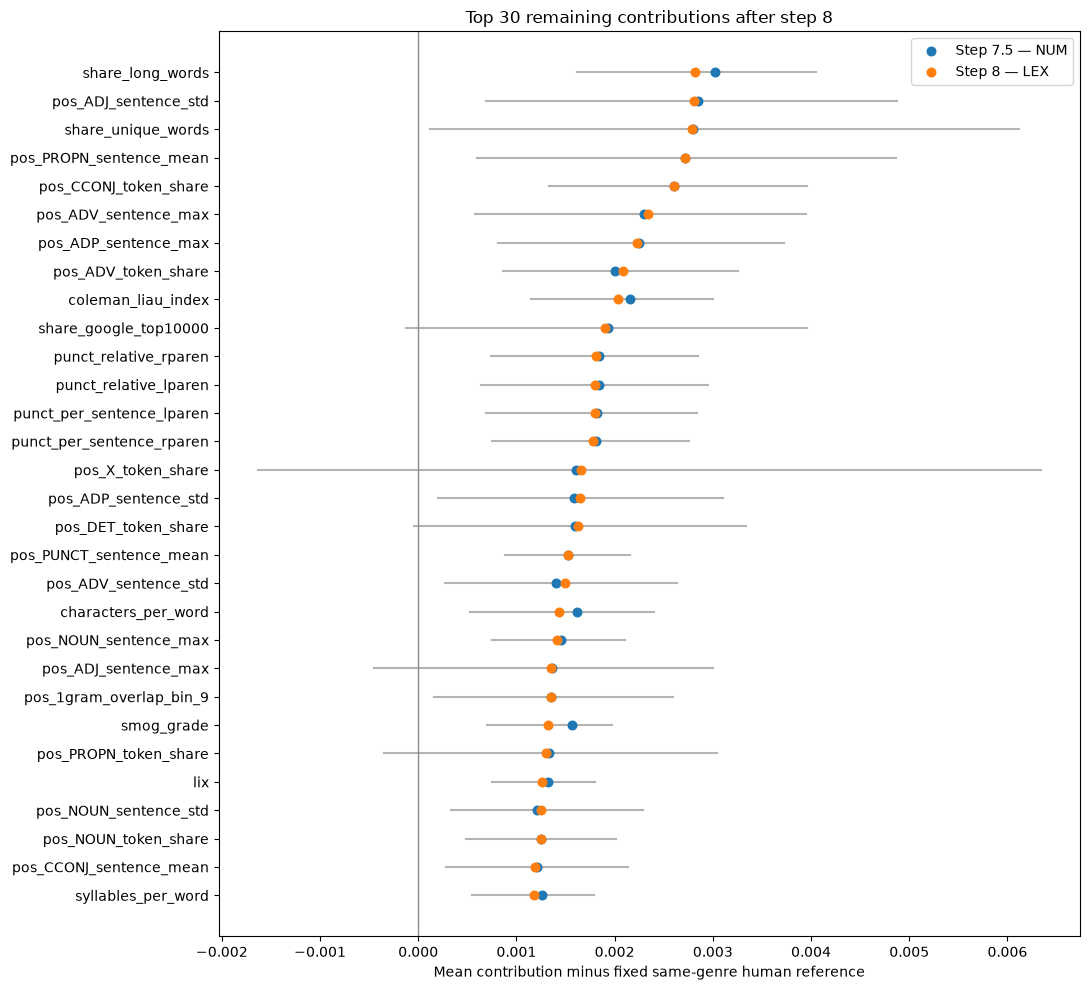

,feature,NUM_gap,LEX_gap,LEX_minus_NUM,LEX_ci_low,LEX_ci_high
12,share_long_words,0.003026,0.002816,-0.000210,0.001614,0.004045
120,pos_ADJ_sentence_std,0.002849,0.002808,-0.000041,0.000685,0.004876
23,share_unique_words,0.002793,0.002786,-0.000007,0.000117,0.006122
163,pos_PROPN_sentence_mean,0.002720,0.002717,-0.000003,0.000600,0.004864
134,pos_CCONJ_token_share,0.002607,0.002604,-0.000003,0.001336,0.003964
129,pos_ADV_sentence_max,0.002304,0.002338,0.000034,0.000577,0.003950
125,pos_ADP_sentence_max,0.002252,0.002225,-0.000028,0.000809,0.003720
126,pos_ADV_token_share,0.002004,0.002084,0.000080,0.000866,0.003251
14,coleman_liau_index,0.002153,0.002029,-0.000124,0.001148,0.002997
26,share_google_top10000,0.001936,0.001905,-0.000031,-0.000129,0.003954


In [14]:
# C03e — contribution comparison: Step 7.5 NUM vs Step 8 LEX only.

# Rank by CURRENT Step-8 residual contribution.
top = (
    contribution_change
    .sort_values(
        "LEX_gap",
        ascending=False,
    )
    .head(30)
    .copy()
)

# Reverse so largest appears at the top of the horizontal plot.
top = (
    top.iloc[::-1]
    .reset_index(drop=True)
)

y = np.arange(len(top))

fig, ax = plt.subplots(
    figsize=(11, 10)
)

# Step-8 bootstrap 95% CI.
for i, row in top.iterrows():
    ax.plot(
        [
            row["LEX_ci_low"],
            row["LEX_ci_high"],
        ],
        [i, i],
        color="0.70",
        linewidth=1.5,
        zorder=1,
    )

# Before intervention: Step 7.5 NUM.
ax.scatter(
    top["NUM_gap"],
    y,
    s=38,
    label="Step 7.5 — NUM",
    zorder=3,
)

# After intervention: Step 8 LEX.
ax.scatter(
    top["LEX_gap"],
    y,
    s=38,
    label="Step 8 — LEX",
    zorder=4,
)

ax.axvline(
    0,
    color="0.55",
    linewidth=1,
)

ax.set_yticks(y)

ax.set_yticklabels(
    top["feature"]
)

ax.set_xlabel(
    "Mean contribution minus fixed same-genre human reference"
)

ax.set_title(
    "Top 30 remaining contributions after step 8"
)

ax.legend(
    loc="upper right"
)

fig.tight_layout()

for ext in ("png", "pdf"):
    fig.savefig(
        STEP8_OUT
        / f"C03e_NUM_vs_LEX_remaining_contributions.{ext}",
        dpi=300,
        bbox_inches="tight",
    )

    fig.savefig(
        FIG
        / f"C03e_NUM_vs_LEX_remaining_contributions.{ext}",
        dpi=300,
        bbox_inches="tight",
    )

plt.show()


# Numerical companion table.
comparison = (
    contribution_change
    .assign(
        abs_change=lambda d:
            d["LEX_minus_NUM"].abs()
    )
    .sort_values(
        "LEX_gap",
        ascending=False,
    )
)

display(
    comparison[
        [
            "feature",
            "NUM_gap",
            "LEX_gap",
            "LEX_minus_NUM",
            "LEX_ci_low",
            "LEX_ci_high",
        ]
    ].head(30)
)

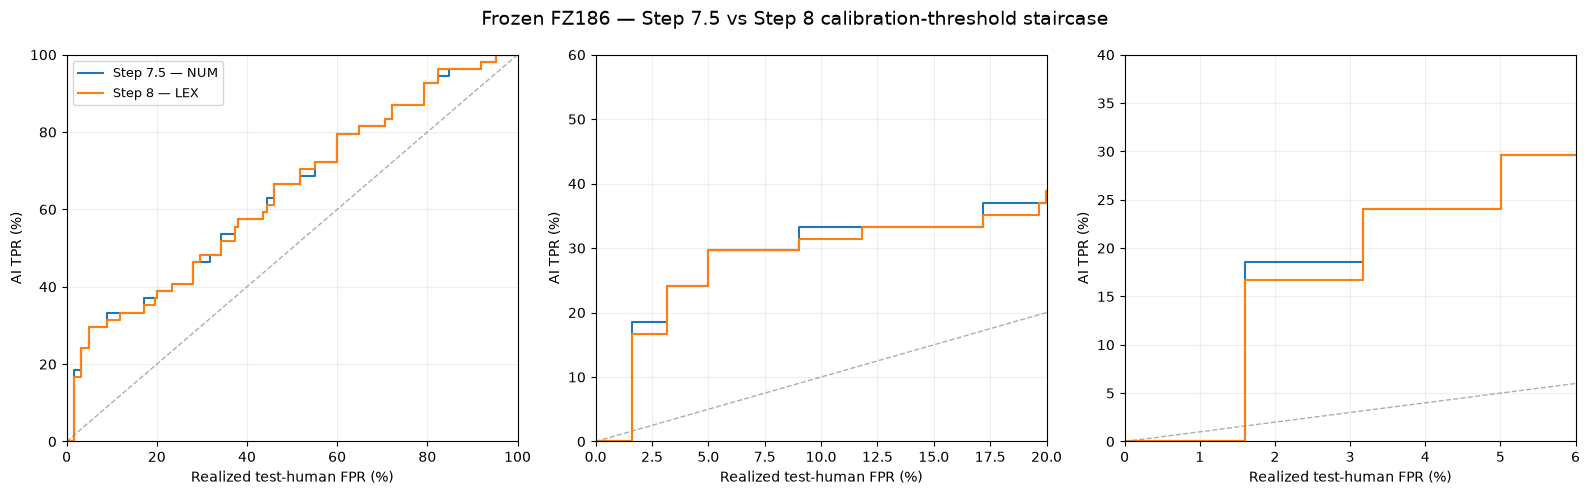

,requested_calibration_FPR,achieved_calibration_FPR,realized_test_FPR,Step 7.5 — NUM,Step 8 — LEX,LEX_minus_NUM_TPR
0,0.010,0.008418,0.015988,0.111111,0.092593,-1.851852e-02
1,0.020,0.023232,0.015988,0.185185,0.166667,-1.851852e-02
2,0.030,0.032492,0.031704,0.222222,0.222222,0.000000e+00
3,0.050,0.049798,0.038906,0.240741,0.240741,2.775558e-17
4,0.075,0.076364,0.050044,0.277778,0.259259,-1.851852e-02
5,0.100,0.099596,0.050044,0.296296,0.296296,0.000000e+00
6,0.150,0.145915,0.090277,0.333333,0.314815,-1.851852e-02
7,0.200,0.201592,0.118355,0.333333,0.333333,0.000000e+00
8,0.300,0.303960,0.280297,0.462963,0.444444,-1.851852e-02
9,0.500,0.497691,0.405241,0.574074,0.574074,0.000000e+00


In [15]:
# C03e — TPR staircase: Step 7.5 NUM vs Step 8 LEX.
# Reuses the exact C03d calibration thresholds and realized test-human FPR.

previous_staircase = pd.read_csv(
    FINAL_DIR / "detailed_TPR_staircase.csv"
)

required = {
    "threshold",
    "calibration_FPR",
    "test_FPR",
    "Step 7.5 — NUM",
}

assert required <= set(
    previous_staircase.columns
)

thresholds = (
    previous_staircase["threshold"]
    .astype(float)
    .to_numpy()
)

staircase = previous_staircase[
    [
        "threshold",
        "calibration_FPR",
        "test_FPR",
        "Step 7.5 — NUM",
    ]
].copy()

# Add Step 8 from the newly computed lexical-treatment scores.
staircase["Step 8 — LEX"] = [
    np.mean(
        lex_scores > threshold
    )
    for threshold in thresholds
]

# Sanity check:
# our saved post-NUM scores must exactly reproduce
# the old Step-7.5 curve.
num_check = np.asarray([
    np.mean(
        num_scores_saved > threshold
    )
    for threshold in thresholds
])

np.testing.assert_allclose(
    num_check,
    staircase["Step 7.5 — NUM"].to_numpy(float),
    atol=1e-12,
    rtol=0,
)

staircase.to_csv(
    STEP8_OUT
    / "C03e_NUM_vs_LEX_TPR_staircase.csv",
    index=False,
)


# ------------------------------------------------------------
# Plot in the same 3-panel style as the C03d figure.
# ------------------------------------------------------------

x = (
    staircase["test_FPR"]
    .to_numpy(float)
    * 100
)

stages = [
    "Step 7.5 — NUM",
    "Step 8 — LEX",
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5),
)

# (x max, y max)
panel_specs = [
    (100, 100),
    (20, 60),
    (6, 40),
]

for ax, (xmax, ymax) in zip(
    axes,
    panel_specs,
):

    for stage in stages:
        ax.step(
            x,
            staircase[stage].to_numpy(float) * 100,
            where="post",
            label=stage,
        )

    # Diagonal reference, matching the previous plots.
    ax.plot(
        [0, xmax],
        [0, xmax],
        "--",
        color="0.55",
        linewidth=1,
        alpha=0.7,
    )

    ax.set_xlim(
        0,
        xmax,
    )

    ax.set_ylim(
        0,
        ymax,
    )

    ax.set_xlabel(
        "Realized test-human FPR (%)"
    )

    ax.set_ylabel(
        "AI TPR (%)"
    )

    ax.grid(
        alpha=0.2
    )

axes[0].legend(
    fontsize=9
)

fig.suptitle(
    "Frozen FZ186 — Step 7.5 vs Step 8 calibration-threshold staircase",
    fontsize=14,
)

fig.tight_layout()

for ext in ("png", "pdf"):

    fig.savefig(
        STEP8_OUT
        / f"C03e_NUM_vs_LEX_TPR_staircase.{ext}",
        dpi=300,
        bbox_inches="tight",
    )

    fig.savefig(
        FIG
        / f"C03e_NUM_vs_LEX_TPR_staircase.{ext}",
        dpi=300,
        bbox_inches="tight",
    )

plt.show()


# ------------------------------------------------------------
# Detailed numerical operating-point table.
# ------------------------------------------------------------

requested_fprs = [
    0.01,
    0.02,
    0.03,
    0.05,
    0.075,
    0.10,
    0.15,
    0.20,
    0.30,
    0.50,
]

cal_fpr = (
    staircase["calibration_FPR"]
    .to_numpy(float)
)

rows = []

for requested in requested_fprs:

    idx = int(
        np.argmin(
            np.abs(
                cal_fpr - requested
            )
        )
    )

    r = staircase.iloc[idx]

    rows.append({
        "requested_calibration_FPR":
            requested,

        "achieved_calibration_FPR":
            float(
                r["calibration_FPR"]
            ),

        "realized_test_FPR":
            float(
                r["test_FPR"]
            ),

        "Step 7.5 — NUM":
            float(
                r["Step 7.5 — NUM"]
            ),

        "Step 8 — LEX":
            float(
                r["Step 8 — LEX"]
            ),

        "LEX_minus_NUM_TPR":
            float(
                r["Step 8 — LEX"]
                - r["Step 7.5 — NUM"]
            ),
    })

tpr_operating_points = pd.DataFrame(
    rows
)

tpr_operating_points.to_csv(
    STEP8_OUT
    / "C03e_NUM_vs_LEX_TPR_operating_points.csv",
    index=False,
)

display(
    tpr_operating_points
)

In [18]:
# C03e wrap-up prerequisite:
# reconstruct the exact frozen FZ186 test-human scores + weights.
#
# This removes the dependency on having run an earlier stage-summary cell.

import hashlib
import json
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Exact frozen human-test manifest used by canonical C03 FZ186.
# ------------------------------------------------------------

HUMAN_TEST_MANIFEST = (
    C03_RUN / "human_test_manifest.csv"
)

assert HUMAN_TEST_MANIFEST.exists(), (
    f"Missing: {HUMAN_TEST_MANIFEST}"
)

human_test_manifest = pd.read_csv(
    HUMAN_TEST_MANIFEST
)

assert {
    "source_id",
    "domain",
    "weight",
} <= set(
    human_test_manifest.columns
)


# ------------------------------------------------------------
# Base RAID inherited FZ118 features + raw text.
# ------------------------------------------------------------

_base_features = (
    pd.read_parquet(
        BASE / "fz118_paired_features.parquet"
    )
    .set_index("source_id")
)

_corpus = (
    pd.read_parquet(
        BASE / "paired_corpus.parquet"
    )
    .set_index("source_id")
)

assert set(
    human_test_manifest["source_id"]
) <= set(
    _base_features.index
)

assert set(
    human_test_manifest["source_id"]
) <= set(
    _corpus.index
)


# ------------------------------------------------------------
# Recover the canonical cached 68 POS coordinates.
#
# This is preferable to recomputing them here because it uses
# the exact vectors frozen by the original C03 FZ186 run.
# ------------------------------------------------------------

def _cached_pos_vector(source_id):

    text = str(
        _corpus.loc[
            source_id,
            "text",
        ]
    )

    key = hashlib.sha256(
        normalize(text).encode()
    ).hexdigest()

    path = (
        C03_RUN
        / "pos_cache"
        / f"{key}.json"
    )

    assert path.exists(), (
        f"Missing POS cache for "
        f"{source_id}: {path}"
    )

    arr = np.asarray(
        json.loads(
            path.read_text()
        ),
        dtype=float,
    )

    assert arr.shape == (68,)

    return arr


# ------------------------------------------------------------
# Construct exact FZ186 human-test matrix.
# ------------------------------------------------------------

human_rows = []

for source_id in human_test_manifest[
    "source_id"
]:

    f118 = (
        _base_features.loc[
            source_id,
            FEATURE_NAMES,
        ]
        .to_numpy(
            dtype=float
        )
    )

    assert f118.shape == (118,)

    pos = _cached_pos_vector(
        source_id
    )

    vector = np.concatenate([
        f118,
        pos,
    ])

    assert vector.shape == (186,)

    human_rows.append(
        vector
    )


X_human_test = pd.DataFrame(
    human_rows,
    columns=F186,
)

assert len(
    X_human_test
) == len(
    human_test_manifest
)

assert np.isfinite(
    X_human_test.to_numpy(float)
).all()


# ------------------------------------------------------------
# Frozen detector scores + the already-frozen genre weights.
# ------------------------------------------------------------

human_test_scores = (
    fz186_model.predict_proba(
        X_human_test[F186]
    )[:, 1]
)

human_weights = (
    human_test_manifest[
        "weight"
    ]
    .astype(float)
    .to_numpy()
)

assert len(
    human_test_scores
) == len(
    human_weights
)

assert (
    human_weights > 0
).all()


print(
    "Human test examples:",
    len(human_test_scores),
)

print(
    "Human weight sum:",
    human_weights.sum(),
)

print(
    "Human score range:",
    f"{human_test_scores.min():.6f}",
    "to",
    f"{human_test_scores.max():.6f}",
)

print(
    "✓ human_test_scores and "
    "human_weights are ready."
)

Human test examples: 128
Human weight sum: 0.9999999999999942
Human score range: 0.159532 to 0.731718
✓ human_test_scores and human_weights are ready.


In [23]:
# C03e wrap-up — compute Original vs Post-FZ118 (1–4) vs Current (5–8)
# on the frozen FZ186 detector.

from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd
import hashlib
from IPython.display import display

required = [
    "ROOT", "BASE", "FINAL_DIR", "STEP8_OUT",
    "texts", "scored_lex_texts",
    "F186", "f186_frame", "fz186_model",
    "num_scores_saved", "lex_scores", "X_num", "X_lex"
]
missing = [x for x in required if x not in globals()]
assert not missing, f"Run the earlier C03e eval cells first. Missing: {missing}"


# ------------------------------------------------------------------
# Helpers
# ------------------------------------------------------------------

def _find_text_col(df):
    for c in ["text", "accepted_text", "treatment", "rewrite", "output_text"]:
        if c in df.columns:
            return c
    raise KeyError(f"Could not find text column in columns={list(df.columns)}")


def weighted_auc(ai_scores, human_scores, human_weights):
    ai_scores = np.asarray(ai_scores, dtype=float)
    y = np.concatenate([
        np.zeros(len(human_scores)),
        np.ones(len(ai_scores)),
    ])
    s = np.concatenate([
        np.asarray(human_scores, dtype=float),
        ai_scores,
    ])
    w = np.concatenate([
        np.asarray(human_weights, dtype=float),
        np.full(len(ai_scores), 1.0 / len(ai_scores)),
    ])
    return roc_auc_score(y, s, sample_weight=w)


if "human_test_scores" not in globals() or "human_weights" not in globals():
    raise RuntimeError(
        "human_test_scores / human_weights not found. "
        "Run the earlier C03e stage-summary cell first."
    )


if "forest_contributions" not in globals():
    def forest_contributions(model, frame):
        X = frame[F186].to_numpy(dtype=np.float32)
        output = np.zeros(X.shape, dtype=float)
        bias = 0.0

        for estimator in model.estimators_:
            tree = estimator.tree_
            value = tree.value[:, 0, :].astype(float)
            denom = value.sum(axis=1)

            prob = np.divide(
                value[:, 1],
                denom,
                out=np.zeros_like(denom, dtype=float),
                where=denom != 0,
            )

            bias += prob[0] / len(model.estimators_)

            for i, row in enumerate(X):
                node = 0
                while tree.children_left[node] != tree.children_right[node]:
                    feat = tree.feature[node]

                    if row[feat] <= tree.threshold[node]:
                        child = tree.children_left[node]
                    else:
                        child = tree.children_right[node]

                    output[i, feat] += (prob[child] - prob[node]) / len(model.estimators_)
                    node = child

        recon = bias + output.sum(axis=1)
        expected = model.predict_proba(X)[:, 1]

        np.testing.assert_allclose(recon, expected, atol=1e-8, rtol=0)
        return output


# ------------------------------------------------------------------
# Stage tables
# ------------------------------------------------------------------

# Current canonical case ordering.
case_frame = (
    texts[["case_id", "source_id", "domain"]]
    .sort_values("case_id")
    .reset_index(drop=True)
)

# Original texts.
corpus = pd.read_parquet(BASE / "paired_corpus.parquet").set_index("source_id")

original_table = case_frame.copy()
original_table["text"] = original_table["source_id"].map(corpus["text"])

assert original_table["text"].notna().all()

# Post-FZ118 (steps 1–4 done).
# ------------------------------------------------------------------
# Post-FZ118 = completed Phase-One / steps 1–4 texts.
# Use the exact 54-text input that canonical C03 FZ186 started from.
# ------------------------------------------------------------------

POST_FZ118_PATH = (
    ROOT
    / "results/causal/C02w_adaptive_camouflage_v1/final_texts_54.csv"
)

assert POST_FZ118_PATH.exists(), (
    f"Missing canonical post-FZ118 input: {POST_FZ118_PATH}"
)

post_fz118_raw = (
    pd.read_csv(
        POST_FZ118_PATH,
        keep_default_na=False,
    )
    .sort_values("case_id")
    .reset_index(drop=True)
)

assert len(post_fz118_raw) == 54
assert post_fz118_raw["case_id"].is_unique
assert post_fz118_raw["source_id"].is_unique
assert post_fz118_raw["pipeline_status"].eq("complete").all()
assert post_fz118_raw["text"].str.strip().ne("").all()

post_fz118_table = (
    post_fz118_raw[
        [
            "case_id",
            "source_id",
            "domain",
            "text",
        ]
    ]
    .sort_values("case_id")
    .reset_index(drop=True)
)

# Must be exactly the same fixed 54 cases as C03e.
assert (
    post_fz118_table[
        [
            "case_id",
            "source_id",
            "domain",
        ]
    ].equals(
        case_frame[
            [
                "case_id",
                "source_id",
                "domain",
            ]
        ]
    )
)

print(
    "✓ Loaded canonical post-FZ118 / steps 1–4 texts:",
    POST_FZ118_PATH,
)

# Current = step 5–8 done (after Step 8 LEX).
current_table = (
    scored_lex_texts[["case_id", "source_id", "domain", "text"]]
    .sort_values("case_id")
    .reset_index(drop=True)
)

assert original_table["case_id"].tolist() == post_fz118_table["case_id"].tolist() == current_table["case_id"].tolist()


# ------------------------------------------------------------------
# Feature extraction (cache to disk)
# ------------------------------------------------------------------

ORIG_F186_PATH = STEP8_OUT / "wrapup_original_fz186.csv"
POST_FZ118_F186_PATH = STEP8_OUT / "wrapup_post_FZ118_fz186.csv"

if ORIG_F186_PATH.exists():
    X_orig = (
        pd.read_csv(ORIG_F186_PATH)
        .set_index("case_id")
        .loc[case_frame["case_id"], F186]
    )
else:
    X_orig = f186_frame(original_table)
    X_orig.reset_index().to_csv(ORIG_F186_PATH, index=False)

if POST_FZ118_F186_PATH.exists():
    X_post_fz118 = (
        pd.read_csv(POST_FZ118_F186_PATH)
        .set_index("case_id")
        .loc[case_frame["case_id"], F186]
    )
else:
    X_post_fz118 = f186_frame(post_fz118_table)
    X_post_fz118.reset_index().to_csv(POST_FZ118_F186_PATH, index=False)

# X_num and X_lex already exist from earlier cells.


# ------------------------------------------------------------------
# Scores
# ------------------------------------------------------------------

original_scores = fz186_model.predict_proba(X_orig[F186])[:, 1]
post_fz118_scores = fz186_model.predict_proba(X_post_fz118[F186])[:, 1]
current_scores = np.asarray(lex_scores, dtype=float)

wrapup_scores = pd.DataFrame({
    "case_id": case_frame["case_id"],
    "source_id": case_frame["source_id"],
    "domain": case_frame["domain"],
    "Original_AI_score": original_scores,
    "Post_FZ118_AI_score": post_fz118_scores,
    "Current_AI_score": current_scores,
})

wrapup_scores.to_csv(
    STEP8_OUT / "wrapup_original_postFZ118_current_scores.csv",
    index=False,
)


# ------------------------------------------------------------------
# AUROC / mean score summary
# ------------------------------------------------------------------

wrapup_stage_summary = pd.DataFrame([
    {
        "stage": "Original",
        "AUROC": weighted_auc(original_scores, human_test_scores, human_weights),
        "mean_AI_score": float(np.mean(original_scores)),
        "n_AI": len(original_scores),
    },
    {
        "stage": "Post-FZ118 (1–4)",
        "AUROC": weighted_auc(post_fz118_scores, human_test_scores, human_weights),
        "mean_AI_score": float(np.mean(post_fz118_scores)),
        "n_AI": len(post_fz118_scores),
    },
    {
        "stage": "Current (5–8)",
        "AUROC": weighted_auc(current_scores, human_test_scores, human_weights),
        "mean_AI_score": float(np.mean(current_scores)),
        "n_AI": len(current_scores),
    },
])

wrapup_stage_summary.to_csv(
    STEP8_OUT / "wrapup_original_postFZ118_current_stage_summary.csv",
    index=False,
)

display(wrapup_stage_summary)


# ------------------------------------------------------------------
# TPR staircase table
# ------------------------------------------------------------------

prev_staircase = pd.read_csv(FINAL_DIR / "detailed_TPR_staircase.csv")
thresholds = prev_staircase["threshold"].astype(float).to_numpy()

wrapup_staircase = prev_staircase[["threshold", "calibration_FPR", "test_FPR"]].copy()
wrapup_staircase["Original"] = [np.mean(original_scores > t) for t in thresholds]
wrapup_staircase["Post-FZ118 (1–4)"] = [np.mean(post_fz118_scores > t) for t in thresholds]
wrapup_staircase["Current (5–8)"] = [np.mean(current_scores > t) for t in thresholds]

wrapup_staircase.to_csv(
    STEP8_OUT / "wrapup_original_postFZ118_current_TPR_staircase.csv",
    index=False,
)


# ------------------------------------------------------------------
# Contribution gaps using the exact fixed human reference from C03d.
# ------------------------------------------------------------------

# Recover the exact per-case fixed human reference used in C03d:
# fixed_ref = NUM contribution - saved NUM case gap
saved_case_gaps = (
    pd.read_csv(FINAL_DIR / "case_contribution_gaps.csv")
    .set_index("case_id")
    .loc[case_frame["case_id"], F186]
)

num_contrib_local = forest_contributions(fz186_model, X_num)
orig_contrib = forest_contributions(fz186_model, X_orig)
post_fz118_contrib = forest_contributions(fz186_model, X_post_fz118)
current_contrib = forest_contributions(fz186_model, X_lex)

fixed_ref = num_contrib_local - saved_case_gaps.to_numpy(float)

orig_case_gaps = orig_contrib - fixed_ref
post_fz118_case_gaps = post_fz118_contrib - fixed_ref
current_case_gaps = current_contrib - fixed_ref

# Current-stage CI (same style as before: CI around final/current estimate).
B = 2000
rng = np.random.default_rng(20260911)
n_cases = len(case_frame)
n_features = len(F186)

boot_current = np.empty((B, n_features), dtype=float)

for b in range(B):
    idx = rng.integers(0, n_cases, size=n_cases)
    boot_current[b] = current_case_gaps[idx].mean(axis=0)

current_ci_low, current_ci_high = np.quantile(boot_current, [0.025, 0.975], axis=0)

wrapup_contrib = pd.DataFrame({
    "feature": F186,
    "Original_gap": orig_case_gaps.mean(axis=0),
    "Post_FZ118_gap": post_fz118_case_gaps.mean(axis=0),
    "Current_gap": current_case_gaps.mean(axis=0),
    "Current_ci_low": current_ci_low,
    "Current_ci_high": current_ci_high,
})

wrapup_contrib.to_csv(
    STEP8_OUT / "wrapup_original_postFZ118_current_contributions.csv",
    index=False,
)

orig_case_gap_frame = pd.DataFrame(orig_case_gaps, columns=F186)
orig_case_gap_frame.insert(0, "case_id", case_frame["case_id"].tolist())
orig_case_gap_frame.to_csv(
    STEP8_OUT / "wrapup_original_case_contribution_gaps.csv",
    index=False,
)

post_fz118_case_gap_frame = pd.DataFrame(post_fz118_case_gaps, columns=F186)
post_fz118_case_gap_frame.insert(0, "case_id", case_frame["case_id"].tolist())
post_fz118_case_gap_frame.to_csv(
    STEP8_OUT / "wrapup_postFZ118_case_contribution_gaps.csv",
    index=False,
)

current_case_gap_frame = pd.DataFrame(current_case_gaps, columns=F186)
current_case_gap_frame.insert(0, "case_id", case_frame["case_id"].tolist())
current_case_gap_frame.to_csv(
    STEP8_OUT / "wrapup_current_case_contribution_gaps.csv",
    index=False,
)

print("Saved wrap-up tables to:", STEP8_OUT)

✓ Loaded canonical post-FZ118 / steps 1–4 texts: ../results/causal/C02w_adaptive_camouflage_v1/final_texts_54.csv


,stage,AUROC,mean_AI_score,n_AI
0,Original,0.875808,0.604191,54
1,Post-FZ118 (1–4),0.800940,0.540866,54
2,Current (5–8),0.650639,0.476988,54


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but ExtraTreesClassifier was fitted with feature names
  warnings.warn(
/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but ExtraTreesClassifier was fitted with feature names
  warnings.warn(
/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but ExtraTreesClassifier was fitted with feature names
  warnings.warn(


Saved wrap-up tables to: ../results/causal/C03e_lexical_micro_substitution/60d5986e77d8


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but ExtraTreesClassifier was fitted with feature names
  warnings.warn(


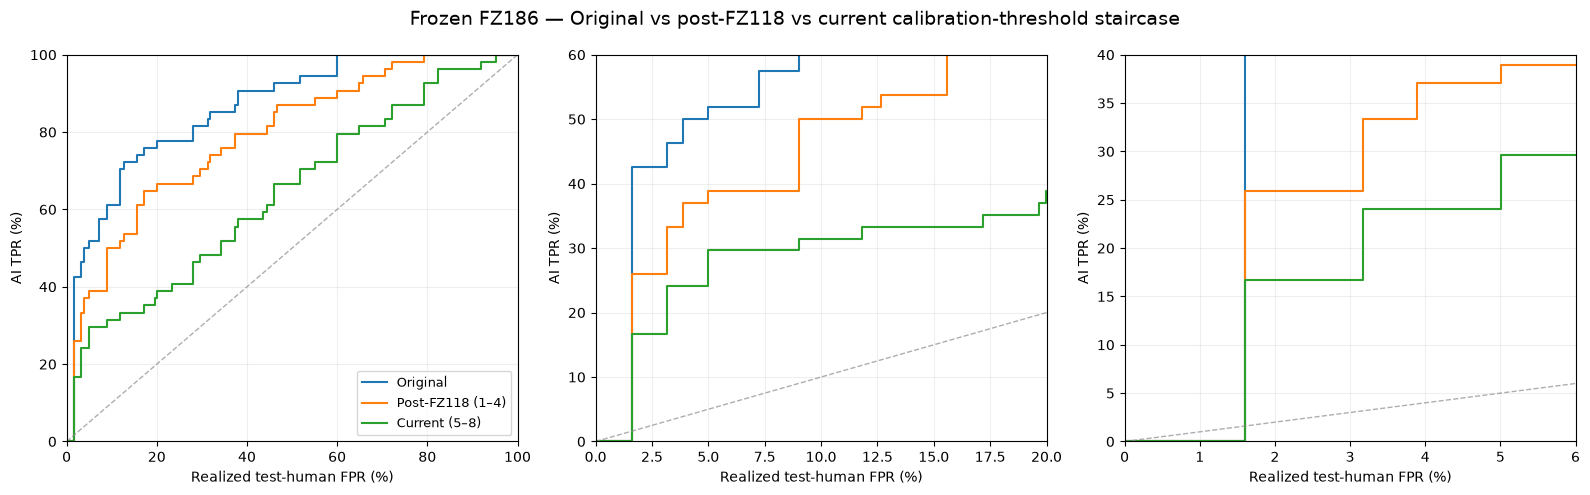

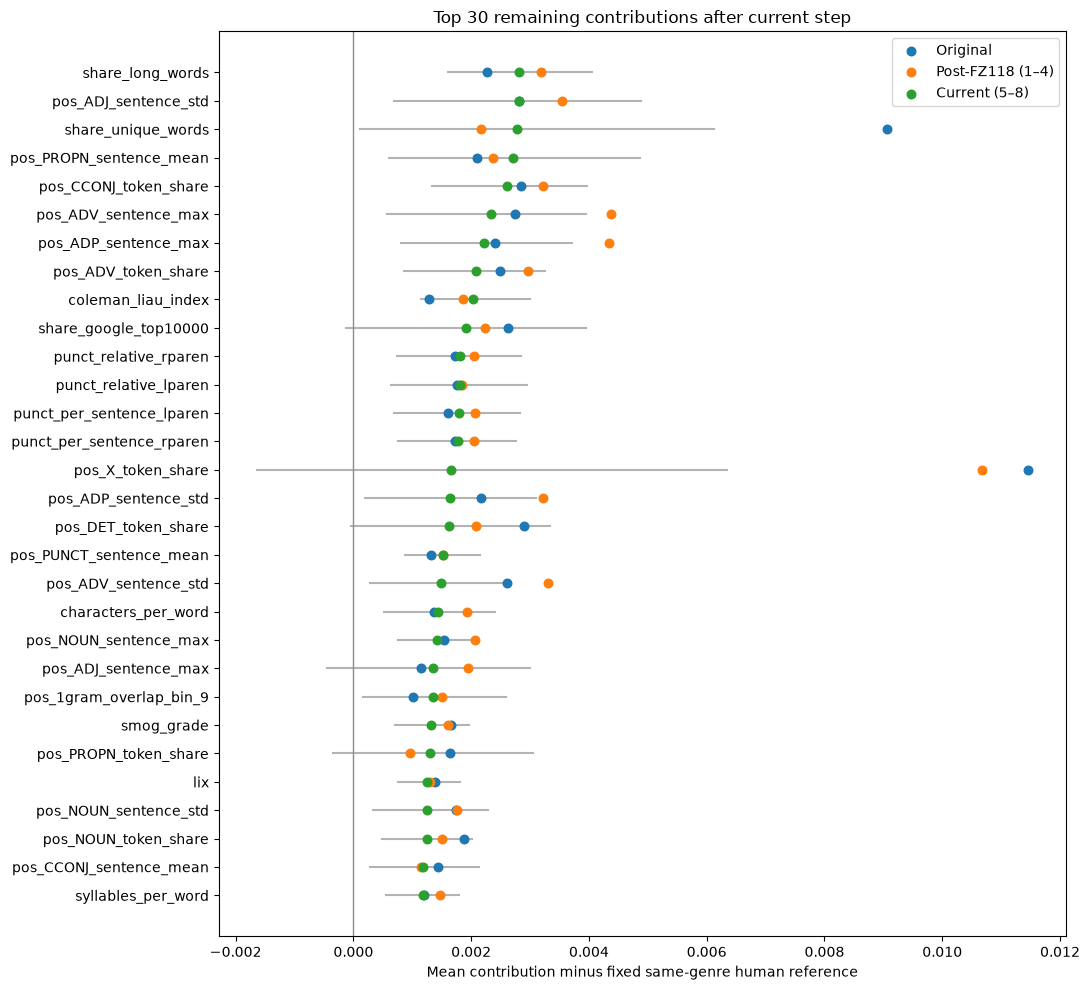

Stage summary:


,stage,AUROC,mean_AI_score,n_AI
0,Original,0.875808,0.604191,54
1,Post-FZ118 (1–4),0.800940,0.540866,54
2,Current (5–8),0.650639,0.476988,54


Top 30 remaining contributions (ranked by current residual):


,feature,Original_gap,Post_FZ118_gap,Current_gap,Current_ci_low,Current_ci_high
0,share_long_words,0.002261,0.003177,0.002816,0.001614,0.004045
1,pos_ADJ_sentence_std,0.002813,0.003549,0.002808,0.000685,0.004876
2,share_unique_words,0.009060,0.002161,0.002786,0.000117,0.006122
3,pos_PROPN_sentence_mean,0.002101,0.002367,0.002717,0.000600,0.004864
4,pos_CCONJ_token_share,0.002851,0.003219,0.002604,0.001336,0.003964
5,pos_ADV_sentence_max,0.002746,0.004376,0.002338,0.000577,0.003950
6,pos_ADP_sentence_max,0.002408,0.004333,0.002225,0.000809,0.003720
7,pos_ADV_token_share,0.002493,0.002961,0.002084,0.000866,0.003251
8,coleman_liau_index,0.001282,0.001855,0.002029,0.001148,0.002997
9,share_google_top10000,0.002624,0.002226,0.001905,-0.000129,0.003954


In [24]:
# C03e wrap-up — plot
# Original vs Post-FZ118 (1–4) vs Current (5–8)
# on frozen FZ186.

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

assert "wrapup_stage_summary" in globals()
assert "wrapup_staircase" in globals()
assert "wrapup_contrib" in globals()

FIG = ROOT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------------
# 1) TPR staircase graph
# ------------------------------------------------------------------

x = wrapup_staircase["test_FPR"].to_numpy(float) * 100
stages = ["Original", "Post-FZ118 (1–4)", "Current (5–8)"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

panel_specs = [
    (100, 100),
    (20, 60),
    (6, 40),
]

for ax, (xmax, ymax) in zip(axes, panel_specs):
    for stage in stages:
        ax.step(
            x,
            wrapup_staircase[stage].to_numpy(float) * 100,
            where="post",
            label=stage,
        )

    ax.plot(
        [0, xmax],
        [0, xmax],
        "--",
        color="0.55",
        linewidth=1,
        alpha=0.7,
    )

    ax.set_xlim(0, xmax)
    ax.set_ylim(0, ymax)
    ax.set_xlabel("Realized test-human FPR (%)")
    ax.set_ylabel("AI TPR (%)")
    ax.grid(alpha=0.2)

axes[0].legend(fontsize=9)

fig.suptitle(
    "Frozen FZ186 — Original vs post-FZ118 vs current calibration-threshold staircase",
    fontsize=14,
)

fig.tight_layout()

for ext in ("png", "pdf"):
    fig.savefig(
        STEP8_OUT / f"wrapup_original_postFZ118_current_TPR_staircase.{ext}",
        dpi=300,
        bbox_inches="tight",
    )
    fig.savefig(
        FIG / f"wrapup_original_postFZ118_current_TPR_staircase.{ext}",
        dpi=300,
        bbox_inches="tight",
    )

plt.show()


# ------------------------------------------------------------------
# 2) Contribution graph
# ------------------------------------------------------------------

top = (
    wrapup_contrib
    .sort_values("Current_gap", ascending=False)
    .head(30)
    .copy()
)

top = top.iloc[::-1].reset_index(drop=True)
y = np.arange(len(top))

fig, ax = plt.subplots(figsize=(11, 10))

# Gray CI bar for final/current estimate.
for i, row in top.iterrows():
    ax.plot(
        [row["Current_ci_low"], row["Current_ci_high"]],
        [i, i],
        color="0.70",
        linewidth=1.5,
        zorder=1,
    )

# 3 dots.
ax.scatter(
    top["Original_gap"],
    y,
    s=38,
    label="Original",
    zorder=3,
)

ax.scatter(
    top["Post_FZ118_gap"],
    y,
    s=38,
    label="Post-FZ118 (1–4)",
    zorder=4,
)

ax.scatter(
    top["Current_gap"],
    y,
    s=38,
    label="Current (5–8)",
    zorder=5,
)

ax.axvline(0, color="0.55", linewidth=1)

ax.set_yticks(y)
ax.set_yticklabels(top["feature"])

ax.set_xlabel("Mean contribution minus fixed same-genre human reference")
ax.set_title("Top 30 remaining contributions after current step")
ax.legend(loc="upper right")

fig.tight_layout()

for ext in ("png", "pdf"):
    fig.savefig(
        STEP8_OUT / f"wrapup_original_postFZ118_current_contributions.{ext}",
        dpi=300,
        bbox_inches="tight",
    )
    fig.savefig(
        FIG / f"wrapup_original_postFZ118_current_contributions.{ext}",
        dpi=300,
        bbox_inches="tight",
    )

plt.show()


# ------------------------------------------------------------------
# Tables
# ------------------------------------------------------------------

print("Stage summary:")
display(wrapup_stage_summary)

print("Top 30 remaining contributions (ranked by current residual):")
display(
    top[
        [
            "feature",
            "Original_gap",
            "Post_FZ118_gap",
            "Current_gap",
            "Current_ci_low",
            "Current_ci_high",
        ]
    ].iloc[::-1].reset_index(drop=True)
)

# Adaptive Camouflage

In [26]:
# C03e final robustness test — Adaptive Camouflage on frozen FZ186.
#
# 20 current Step-8 texts -> added to original RAID train as AI examples.
# Remaining 34 -> completely held out for evaluation.
#
# Reproduce the same genre-stratified random split logic as C02w.

from sklearn.base import clone
from sklearn.metrics import roc_auc_score
import pickle
import hashlib
import json
import numpy as np
import pandas as pd
from IPython.display import display

AC_SEED = 20260909
AC_OUT = ROOT / "results/causal/C03e_FZ186_adaptive_camouflage"
AC_OUT.mkdir(parents=True, exist_ok=True)

assert len(scored_lex_texts) == 54
assert scored_lex_texts["case_id"].is_unique
assert X_lex.shape == (54, 186)

# ------------------------------------------------------------
# 20/34 genre-stratified random split.
# Same algorithm/seed as the old Adaptive Camouflage experiment.
# ------------------------------------------------------------

ac_selection = (
    scored_lex_texts[
        ["case_id", "source_id", "domain"]
    ]
    .sort_values("case_id")
    .reset_index(drop=True)
)

counts = (
    ac_selection["domain"]
    .value_counts()
    .sort_index()
)

quota = counts * 20 / 54

allocation = (
    np.floor(quota)
    .astype(int)
)

# Largest-remainder allocation to exactly 20.
remaining = 20 - int(allocation.sum())

for domain in sorted(
    counts.index,
    key=lambda d: (
        -(quota[d] - allocation[d]),
        d,
    ),
)[:remaining]:
    allocation[domain] += 1


rng = np.random.default_rng(
    AC_SEED
)

adapt_case_ids = []

for domain in counts.index:

    ids = (
        ac_selection.loc[
            ac_selection["domain"].eq(domain),
            "case_id",
        ]
        .to_numpy()
        .copy()
    )

    rng.shuffle(ids)

    adapt_case_ids.extend(
        ids[:allocation[domain]]
    )


ac_selection["role"] = np.where(
    ac_selection["case_id"].isin(adapt_case_ids),
    "adaptation",
    "test",
)

assert (
    ac_selection["role"]
    .eq("adaptation")
    .sum()
    == 20
)

assert (
    ac_selection["role"]
    .eq("test")
    .sum()
    == 34
)

ac_selection.to_csv(
    AC_OUT / "split.csv",
    index=False,
)

display(
    pd.crosstab(
        ac_selection["domain"],
        ac_selection["role"],
    )
)

print(
    "Adaptation:",
    ac_selection.loc[
        ac_selection.role.eq("adaptation"),
        "case_id",
    ].tolist(),
)

print(
    "\nHeld-out test:",
    ac_selection.loc[
        ac_selection.role.eq("test"),
        "case_id",
    ].tolist(),
)


# ------------------------------------------------------------
# Reconstruct exact original RAID FZ186 training matrix.
# ------------------------------------------------------------

raid_features = pd.read_parquet(
    BASE / "fz118_paired_features.parquet"
)

raid_corpus = pd.read_parquet(
    BASE / "paired_corpus.parquet"
)

assert raid_features["source_id"].is_unique
assert raid_corpus["source_id"].is_unique

text_map = (
    raid_corpus
    .set_index("source_id")["text"]
    .to_dict()
)


raid_train = (
    raid_features.loc[
        raid_features["dataset"].eq("raid")
        & raid_features["split"].eq("train")
    ]
    .copy()
    .reset_index(drop=True)
)

assert set(
    ac_selection["source_id"]
).isdisjoint(
    raid_train["source_id"]
)


def cached_c03_pos(source_id):

    text = str(
        text_map[source_id]
    )

    key = hashlib.sha256(
        normalize(text).encode()
    ).hexdigest()

    path = (
        C03_RUN
        / "pos_cache"
        / f"{key}.json"
    )

    assert path.exists(), (
        f"Missing canonical C03 POS cache: {path}"
    )

    values = np.asarray(
        json.loads(
            path.read_text()
        ),
        dtype=float,
    )

    assert values.shape == (68,)

    return values


train_pos = np.vstack([
    cached_c03_pos(source_id)
    for source_id
    in raid_train["source_id"]
])

X_base = pd.concat(
    [
        raid_train[
            FEATURE_NAMES
        ].reset_index(drop=True),

        pd.DataFrame(
            train_pos,
            columns=POS_NAMES,
        ),
    ],
    axis=1,
)

X_base = X_base[F186]

y_base = (
    raid_train["label"]
    .astype(int)
    .reset_index(drop=True)
)

assert X_base.shape[1] == 186
assert np.isfinite(
    X_base.to_numpy(float)
).all()


# ------------------------------------------------------------
# Current Step-8 texts selected for adaptation.
# ------------------------------------------------------------

adapt_ids = (
    ac_selection.loc[
        ac_selection["role"].eq("adaptation"),
        "case_id",
    ]
    .tolist()
)

test_ids = (
    ac_selection.loc[
        ac_selection["role"].eq("test"),
        "case_id",
    ]
    .tolist()
)

X_current = (
    X_lex
    .loc[
        ac_selection["case_id"],
        F186,
    ]
)

X_adapt = (
    X_current
    .loc[adapt_ids]
    .reset_index(drop=True)
)

X_test34 = (
    X_current
    .loc[test_ids]
)

assert len(X_adapt) == 20
assert len(X_test34) == 34


# ------------------------------------------------------------
# Retrain FZ186:
# original RAID train + 20 current camouflage texts labeled AI.
# ------------------------------------------------------------

adapted_fz186 = clone(
    fz186_model
)

assert (
    adapted_fz186.random_state
    == fz186_model.random_state
)

X_fit = pd.concat(
    [
        X_base,
        X_adapt,
    ],
    ignore_index=True,
)

y_fit = pd.concat(
    [
        y_base,
        pd.Series(
            np.ones(
                len(X_adapt),
                dtype=int,
            )
        ),
    ],
    ignore_index=True,
)

assert len(X_fit) == len(y_fit)
assert y_fit.iloc[-20:].eq(1).all()

adapted_fz186.fit(
    X_fit,
    y_fit,
)

with (
    AC_OUT / "FZ186_adapted_20.pkl"
).open("wb") as f:
    pickle.dump(
        adapted_fz186,
        f,
    )

print()
print(
    "Base RAID train:",
    len(X_base),
)

print(
    "Added current AI:",
    len(X_adapt),
)

print(
    "Fit total:",
    len(X_fit),
)

print(
    "Held-out current AI:",
    len(X_test34),
)

print(
    "✓ Adapted FZ186 trained; "
    "34 current texts untouched."
)

role,adaptation,test
domain,,
abstracts,4,6
books,3,4
news,5,7
recipes,3,6
reddit,2,4
reviews,0,1
wiki,3,6


Adaptation: ['gate_0001', 'gate_0004', 'gate_0007', 'gate_0017', 'gate_0019', 'gate_0021', 'gate_0028', 'gate_0037', 'gate_0049', 'gate_0050', 'gate_0054', 'gate_0065', 'gate_0066', 'gate_0069', 'gate_0070', 'gate_0074', 'gate_0075', 'gate_0078', 'gate_0088', 'gate_0093']

Held-out test: ['gate_0003', 'gate_0005', 'gate_0015', 'gate_0016', 'gate_0018', 'gate_0020', 'gate_0022', 'gate_0023', 'gate_0024', 'gate_0025', 'gate_0026', 'gate_0027', 'gate_0030', 'gate_0035', 'gate_0038', 'gate_0039', 'gate_0046', 'gate_0047', 'gate_0048', 'gate_0051', 'gate_0062', 'gate_0067', 'gate_0073', 'gate_0076', 'gate_0079', 'gate_0081', 'gate_0082', 'gate_0085', 'gate_0086', 'gate_0089', 'gate_0090', 'gate_0092', 'gate_0094', 'gate_0095']

Base RAID train: 1272
Added current AI: 20
Fit total: 1292
Held-out current AI: 34
✓ Adapted FZ186 trained; 34 current texts untouched.


In [27]:
# Score exactly the same 34 held-out Step-8 texts
# against Frozen FZ186 and Adapted FZ186.

frozen_34 = (
    fz186_model.predict_proba(
        X_test34[F186]
    )[:, 1]
)

adapted_34 = (
    adapted_fz186.predict_proba(
        X_test34[F186]
    )[:, 1]
)


test_meta = (
    ac_selection
    .set_index("case_id")
    .loc[test_ids]
    .reset_index()
)

adaptive_scores = test_meta.copy()

adaptive_scores[
    "Frozen_FZ186_score"
] = frozen_34

adaptive_scores[
    "Adapted_FZ186_score"
] = adapted_34

adaptive_scores[
    "score_change"
] = (
    adaptive_scores[
        "Adapted_FZ186_score"
    ]
    -
    adaptive_scores[
        "Frozen_FZ186_score"
    ]
)

adaptive_scores.to_csv(
    AC_OUT
    / "heldout34_scores.csv",
    index=False,
)

display(
    adaptive_scores
    .sort_values(
        "score_change",
        ascending=False,
    )
)


print("=" * 72)

print(
    "HELD-OUT 34 CURRENT TEXTS"
)

print(
    f"Frozen FZ186 mean score:  "
    f"{frozen_34.mean():.6f}"
)

print(
    f"Adapted FZ186 mean score: "
    f"{adapted_34.mean():.6f}"
)

print(
    f"Mean score recovery:      "
    f"{(adapted_34 - frozen_34).mean():+.6f}"
)

print(
    f"Score increased on:       "
    f"{(adapted_34 > frozen_34).sum()}/34"
)

print("=" * 72)

,case_id,source_id,domain,role,Frozen_FZ186_score,Adapted_FZ186_score,score_change
28,gate_0086,ai__raid:7ced28f5-df4d-40ba-a6f1-e7fa8fbb9640,wiki,test,0.392690,0.461901,0.069211
29,gate_0089,ai__raid:788e4594-960c-4621-8b5e-6f82b7552d7b,recipes,test,0.247962,0.312966,0.065003
11,gate_0027,ai__raid:f3cc8b87-5e7a-49cb-bc52-a57b28ce27d2,wiki,test,0.442305,0.504704,0.062399
13,gate_0035,ai__raid:e0c2314e-b8d9-422e-af55-1498f8c4dce9,books,test,0.477716,0.537681,0.059965
27,gate_0085,ai__raid:fa8bd0e4-3134-4d4d-83e4-4749c0bf6462,recipes,test,0.413685,0.463274,0.049589
21,gate_0067,ai__raid:5f29c85e-2c0c-402d-a985-d5f9974352d8,recipes,test,0.334054,0.379693,0.045639
9,gate_0025,ai__raid:dab3ef7f-6a54-49f9-9367-e907f0618c82,recipes,test,0.589144,0.634553,0.045409
18,gate_0048,ai__raid:b0d2e4eb-3c43-49ce-bfe1-9a6eafef8b02,news,test,0.370890,0.412045,0.041155
14,gate_0038,ai__raid:bf3df034-9724-4840-86cb-33eb1489b717,reddit,test,0.491761,0.531439,0.039678
24,gate_0079,ai__raid:48ea9a1e-7e86-41ee-a3bb-4675af0442ef,abstracts,test,0.304174,0.340081,0.035907


HELD-OUT 34 CURRENT TEXTS
Frozen FZ186 mean score:  0.478855
Adapted FZ186 mean score: 0.497615
Mean score recovery:      +0.018760
Score increased on:       25/34


In [28]:
# Adaptive Camouflage — held-out AUROC.
#
# Human test pool stays fixed, but each detector scores it separately.

assert "X_human_test" in globals()
assert "human_weights" in globals()

frozen_human = (
    fz186_model.predict_proba(
        X_human_test[F186]
    )[:, 1]
)

adapted_human = (
    adapted_fz186.predict_proba(
        X_human_test[F186]
    )[:, 1]
)


def weighted_ai_human_auc(
    human_scores,
    ai_scores,
):
    human_scores = np.asarray(
        human_scores,
        dtype=float,
    )

    ai_scores = np.asarray(
        ai_scores,
        dtype=float,
    )

    y = np.concatenate([
        np.zeros(
            len(human_scores)
        ),
        np.ones(
            len(ai_scores)
        ),
    ])

    scores = np.concatenate([
        human_scores,
        ai_scores,
    ])

    # Preserve canonical human genre weights;
    # give the 34 AI cases total mass 1.
    weights = np.concatenate([
        human_weights,
        np.full(
            len(ai_scores),
            1.0 / len(ai_scores),
        ),
    ])

    return roc_auc_score(
        y,
        scores,
        sample_weight=weights,
    )


frozen_auc34 = (
    weighted_ai_human_auc(
        frozen_human,
        frozen_34,
    )
)

adapted_auc34 = (
    weighted_ai_human_auc(
        adapted_human,
        adapted_34,
    )
)


adaptive_summary = pd.DataFrame([
    {
        "detector":
            "Frozen FZ186",

        "n_adaptation_AI":
            0,

        "n_test_AI":
            34,

        "AUROC":
            frozen_auc34,

        "mean_test_AI_score":
            frozen_34.mean(),

        "mean_human_score":
            np.average(
                frozen_human,
                weights=human_weights,
            ),
    },

    {
        "detector":
            "Adapted FZ186 (+20 current AI)",

        "n_adaptation_AI":
            20,

        "n_test_AI":
            34,

        "AUROC":
            adapted_auc34,

        "mean_test_AI_score":
            adapted_34.mean(),

        "mean_human_score":
            np.average(
                adapted_human,
                weights=human_weights,
            ),
    },
])

adaptive_summary[
    "AUROC_change_vs_frozen"
] = (
    adaptive_summary["AUROC"]
    - frozen_auc34
)

adaptive_summary.to_csv(
    AC_OUT
    / "adaptive_camouflage_summary.csv",
    index=False,
)

display(
    adaptive_summary
)

print(
    f"AUROC recovery after seeing "
    f"20/54 current examples: "
    f"{adapted_auc34 - frozen_auc34:+.6f}"
)

,detector,n_adaptation_AI,n_test_AI,AUROC,mean_test_AI_score,mean_human_score,AUROC_change_vs_frozen
0,Frozen FZ186,0,34,0.647886,0.478855,0.402992,0.000000
1,Adapted FZ186 (+20 current AI),20,34,0.684254,0.497615,0.410994,0.036368


AUROC recovery after seeing 20/54 current examples: +0.036368


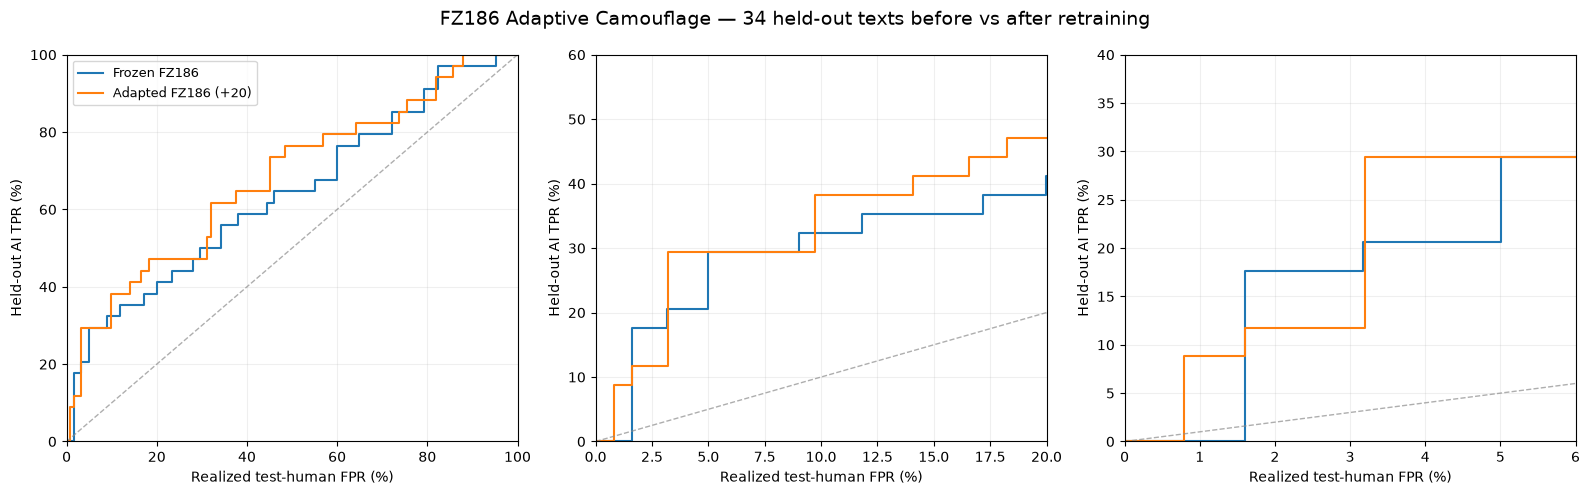

,detector,requested_calibration_FPR,threshold,achieved_calibration_FPR,realized_test_FPR,heldout34_TPR
0,Frozen FZ186,0.01,0.653783,0.008418,0.015988,0.117647
1,Frozen FZ186,0.05,0.602644,0.049798,0.038906,0.205882
2,Frozen FZ186,0.10,0.589020,0.099596,0.050044,0.294118
3,Frozen FZ186,0.20,0.520601,0.192703,0.118355,0.352941
4,Frozen FZ186,0.30,0.476262,0.294700,0.233352,0.441176
5,Frozen FZ186,0.50,0.420166,0.497691,0.405241,0.588235
6,Adapted FZ186 (+20 current AI),0.01,0.657736,0.008418,0.015988,0.117647
7,Adapted FZ186 (+20 current AI),0.05,0.610213,0.049798,0.031962,0.294118
8,Adapted FZ186 (+20 current AI),0.10,0.600600,0.092189,0.040013,0.294118
9,Adapted FZ186 (+20 current AI),0.20,0.538520,0.194184,0.090277,0.294118


In [29]:
# C03e Adaptive Camouflage — detailed TPR staircase
# Frozen FZ186 vs FZ186 retrained with 20 current AI examples.
#
# Each detector independently:
#   1. scores the SAME frozen calibration-human pool,
#   2. sweeps all distinct calibration-human thresholds,
#   3. uses strict score > threshold,
#   4. reports realized FPR on the SAME frozen test-human pool,
#   5. reports TPR on the SAME 34 held-out current AI texts.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hashlib
import json

# ------------------------------------------------------------------
# Recover canonical calibration-human manifest.
# ------------------------------------------------------------------

CAL_MANIFEST = (
    C03_RUN
    / "human_calibration_manifest.csv"
)

assert CAL_MANIFEST.exists(), (
    f"Missing: {CAL_MANIFEST}"
)

human_calibration_manifest = pd.read_csv(
    CAL_MANIFEST
)

assert {
    "source_id",
    "domain",
    "weight",
} <= set(
    human_calibration_manifest.columns
)


# ------------------------------------------------------------------
# Make sure canonical RAID feature/corpus tables are available.
# ------------------------------------------------------------------

if "_base_features" not in globals():
    _base_features = (
        pd.read_parquet(
            BASE / "fz118_paired_features.parquet"
        )
        .set_index("source_id")
    )

if "_corpus" not in globals():
    _corpus = (
        pd.read_parquet(
            BASE / "paired_corpus.parquet"
        )
        .set_index("source_id")
    )


def _canonical_pos_for_source(source_id):

    text = str(
        _corpus.loc[
            source_id,
            "text",
        ]
    )

    key = hashlib.sha256(
        normalize(text).encode()
    ).hexdigest()

    path = (
        C03_RUN
        / "pos_cache"
        / f"{key}.json"
    )

    assert path.exists(), (
        f"Missing POS cache: {path}"
    )

    x = np.asarray(
        json.loads(
            path.read_text()
        ),
        dtype=float,
    )

    assert x.shape == (68,)

    return x


def canonical_human_matrix(manifest_df):

    rows = []

    for sid in manifest_df[
        "source_id"
    ]:

        inherited = (
            _base_features.loc[
                sid,
                FEATURE_NAMES,
            ]
            .to_numpy(float)
        )

        pos = (
            _canonical_pos_for_source(
                sid
            )
        )

        x = np.concatenate([
            inherited,
            pos,
        ])

        assert x.shape == (186,)

        rows.append(x)

    return pd.DataFrame(
        rows,
        columns=F186,
    )


# ------------------------------------------------------------------
# Calibration-human FZ186 vectors.
# ------------------------------------------------------------------

X_human_calibration = (
    canonical_human_matrix(
        human_calibration_manifest
    )
)

calibration_weights = (
    human_calibration_manifest[
        "weight"
    ]
    .astype(float)
    .to_numpy()
)

assert (
    calibration_weights > 0
).all()


# Test humans were already constructed for the adaptive-AUROC cell.
assert "X_human_test" in globals()
assert "human_weights" in globals()

test_weights = np.asarray(
    human_weights,
    dtype=float,
)


# ------------------------------------------------------------------
# Score humans under EACH detector separately.
# ------------------------------------------------------------------

frozen_calibration_scores = (
    fz186_model.predict_proba(
        X_human_calibration[F186]
    )[:, 1]
)

adapted_calibration_scores = (
    adapted_fz186.predict_proba(
        X_human_calibration[F186]
    )[:, 1]
)

frozen_test_human_scores = (
    fz186_model.predict_proba(
        X_human_test[F186]
    )[:, 1]
)

adapted_test_human_scores = (
    adapted_fz186.predict_proba(
        X_human_test[F186]
    )[:, 1]
)


# The 34 held-out AI scores already exist:
assert len(frozen_34) == 34
assert len(adapted_34) == 34


# ------------------------------------------------------------------
# Detailed calibration-threshold staircase.
# ------------------------------------------------------------------

def detailed_staircase(
    label,
    calibration_scores,
    calibration_weights,
    test_human_scores,
    test_human_weights,
    ai_scores,
):

    calibration_scores = np.asarray(
        calibration_scores,
        dtype=float,
    )

    calibration_weights = np.asarray(
        calibration_weights,
        dtype=float,
    )

    test_human_scores = np.asarray(
        test_human_scores,
        dtype=float,
    )

    test_human_weights = np.asarray(
        test_human_weights,
        dtype=float,
    )

    ai_scores = np.asarray(
        ai_scores,
        dtype=float,
    )

    # Normalize independently to total human mass 1.
    cw = (
        calibration_weights
        / calibration_weights.sum()
    )

    tw = (
        test_human_weights
        / test_human_weights.sum()
    )

    # All distinct calibration-human thresholds.
    # +inf gives (0,0); -inf gives (1,1).
    cuts = np.concatenate([
        [np.inf],
        np.sort(
            np.unique(
                calibration_scores
            )
        )[::-1],
        [-np.inf],
    ])

    rows = []

    for threshold in cuts:

        cal_fpr = float(
            cw[
                calibration_scores
                > threshold
            ].sum()
        )

        test_fpr = float(
            tw[
                test_human_scores
                > threshold
            ].sum()
        )

        tpr = float(
            np.mean(
                ai_scores
                > threshold
            )
        )

        rows.append({
            "detector":
                label,

            "threshold":
                threshold,

            "calibration_FPR":
                cal_fpr,

            "test_FPR":
                test_fpr,

            "TPR":
                tpr,
        })

    return pd.DataFrame(rows)


frozen_staircase = detailed_staircase(
    "Frozen FZ186",
    frozen_calibration_scores,
    calibration_weights,
    frozen_test_human_scores,
    test_weights,
    frozen_34,
)

adapted_staircase = detailed_staircase(
    "Adapted FZ186 (+20 current AI)",
    adapted_calibration_scores,
    calibration_weights,
    adapted_test_human_scores,
    test_weights,
    adapted_34,
)

adaptive_staircase = pd.concat(
    [
        frozen_staircase,
        adapted_staircase,
    ],
    ignore_index=True,
)

adaptive_staircase.to_csv(
    AC_OUT
    / "adaptive_camouflage_TPR_staircase.csv",
    index=False,
)


# ------------------------------------------------------------------
# Plot in the established 3-panel C03 style.
# ------------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5),
)

panel_specs = [
    (100, 100),
    (20, 60),
    (6, 40),
]

for ax, (
    xmax,
    ymax,
) in zip(
    axes,
    panel_specs,
):

    for label, frame in [
        (
            "Frozen FZ186",
            frozen_staircase,
        ),
        (
            "Adapted FZ186 (+20)",
            adapted_staircase,
        ),
    ]:

        ax.step(
            frame[
                "test_FPR"
            ].to_numpy(float)
            * 100,

            frame[
                "TPR"
            ].to_numpy(float)
            * 100,

            where="post",
            label=label,
        )

    ax.plot(
        [0, xmax],
        [0, xmax],
        "--",
        color="0.55",
        linewidth=1,
        alpha=0.7,
    )

    ax.set_xlim(
        0,
        xmax,
    )

    ax.set_ylim(
        0,
        ymax,
    )

    ax.set_xlabel(
        "Realized test-human FPR (%)"
    )

    ax.set_ylabel(
        "Held-out AI TPR (%)"
    )

    ax.grid(
        alpha=0.2
    )


axes[0].legend(
    fontsize=9
)

fig.suptitle(
    "FZ186 Adaptive Camouflage — "
    "34 held-out texts before vs after retraining",
    fontsize=14,
)

fig.tight_layout()


for ext in (
    "png",
    "pdf",
):

    fig.savefig(
        AC_OUT
        / f"adaptive_camouflage_TPR_staircase.{ext}",
        dpi=300,
        bbox_inches="tight",
    )

    fig.savefig(
        FIG
        / f"C03e_adaptive_camouflage_TPR_staircase.{ext}",
        dpi=300,
        bbox_inches="tight",
    )


plt.show()


# ------------------------------------------------------------------
# Same requested calibration-FPR operating points for a compact table.
# Each detector uses ITS OWN threshold.
# ------------------------------------------------------------------

BUDGETS = [
    0.01,
    0.05,
    0.10,
    0.20,
    0.30,
    0.50,
]

rows = []

for label, frame in [
    (
        "Frozen FZ186",
        frozen_staircase,
    ),
    (
        "Adapted FZ186 (+20 current AI)",
        adapted_staircase,
    ),
]:

    cf = frame[
        "calibration_FPR"
    ].to_numpy(float)

    for budget in BUDGETS:

        eligible = np.flatnonzero(
            cf <= budget + 1e-12
        )

        # Largest achievable calibration FPR <= requested budget.
        max_cf = cf[
            eligible
        ].max()

        # Of tied rows, use the LAST one so the threshold is
        # the least conservative one at that achieved FPR.
        tied = eligible[
            np.isclose(
                cf[eligible],
                max_cf,
                atol=1e-12,
                rtol=0,
            )
        ]

        idx = int(
            tied[-1]
        )

        r = frame.iloc[
            idx
        ]

        rows.append({
            "detector":
                label,

            "requested_calibration_FPR":
                budget,

            "threshold":
                r["threshold"],

            "achieved_calibration_FPR":
                r["calibration_FPR"],

            "realized_test_FPR":
                r["test_FPR"],

            "heldout34_TPR":
                r["TPR"],
        })


adaptive_operating_points = (
    pd.DataFrame(rows)
)

adaptive_operating_points.to_csv(
    AC_OUT
    / "adaptive_camouflage_TPR_operating_points.csv",
    index=False,
)

display(
    adaptive_operating_points
)